<small>
Introducción a la Ciencia de Datos | Posgrado en Ciencias de la Computación — CICESE  
Práctica 3: Prediccion de desercion estudiantil
</small>

---
# Práctica 3 — Predicción de deserción estudiantil

Clasificador que predice, al cierre del primer semestre, la situación de un estudiante al final de la duración normal de su carrera: **graduado**, **desertor** o **todavía inscrito**. Los datos son de 4424 estudiantes de licenciatura del Instituto Politécnico de Portalegre (Portugal).

#### Descripción del problema e introducción

La deserción universitaria representa un desafío crítico para las instituciones educativas, pues impacta tanto la eficiencia del sistema educativo como el desarrollo socioeconómico de los estudiantes. El objetivo principal de esta práctica es desarrollar un modelo predictivo capaz de anticipar, al término del **primer semestre académico**, el estado final que alcanzará un estudiante al concluir la duración de su programa educativo.

A partir de un conjunto multidimensional de factores socioeconómicos, demográficos y de desempeño académico temprano, se aborda un problema de **clasificación multiclase** con tres posibles resultados finales:

- `Graduate` (Graduado): el estudiante concluyó satisfactoriamente sus estudios.
- `Dropout` (Desertor): el estudiante abandonó de manera definitiva la titulación.
- `Enrolled` (Inscrito/Rezagado): el estudiante continúa matriculado sin haber egresado aún en el tiempo regular.

La detección temprana de estudiantes en riesgo de deserción permite a las instituciones implementar intervenciones oportunas y tutorías personalizadas antes de que la interrupción de los estudios sea irreversible.

#### Descripción del dataset
- **Dataset:** Predict Students' Dropout and Academic Success
- **Fuente:** Repositorio de Aprendizaje Automático de la UC Irvine (UCI Machine Learning Repository)
- **Fecha de creación:** 2021 (publicado por M. V. Martins, V. Realinho et al.)
- **Procedencia:** Instituto Politécnico de Portalegre, Portugal (proyecto financiado por el programa SATDAP, POCI-05-5762-FSE-000191)
- **Qué mide:** factores demográficos, condiciones socioeconómicas, antecedentes académicos de ingreso y rendimiento curricular al cierre del primer y segundo semestre
- **Unidad de observación:** un estudiante universitario matriculado en una titulación de grado
- **Tamaño:**
    - **Tamaño original:** 4424 observaciones y 36 variables predictoras
    - **Subconjunto de entrenamiento** (`desercion-entrenamiento.csv`): 3539 registros (~80 %) con la variable objetivo `Target`
    - **Subconjunto de prueba** (`desercion-prueba.csv`): 885 registros (~20 %) sin la variable objetivo
- **Archivo de salida** (`predicciones.csv`): contiene el identificador de cada estudiante del conjunto de prueba y su categoría predicha (`graduate`, `dropout` o `enrolled`)

#### Estructura del dataset

Las 36 variables predictoras se agrupan en cinco dimensiones principales:

1. **Datos demográficos y personales:**
    - Estado civil, género, edad al momento de la matrícula, nacionalidad, necesidades educativas especiales
2. **Factores socioeconómicos:**
    - Nivel educativo de los padres, ocupación de los padres, condición de becario (`Scholarship holder`), estado de pago de la colegiatura (`Tuition fees up to date`), situación de endeudamiento (`Debtor`)
3. **Antecedentes académicos e ingreso:**
    - Titulación previa de acceso, calificación de ingreso, modo de solicitud/admisión, orden de preferencia de la carrera seleccionada, carrera matriculada (`Course`)
4. **Rendimiento académico del 1er y 2º semestre:**
    - Unidades curriculares acreditadas, inscritas, evaluadas, aprobadas, nota media y unidades curriculares sin evaluación (seis por semestre; las del 2º semestre no se usan en el modelo principal, ver 1.5)
5. **Indicadores macroeconómicos:**
    - Tasa de desempleo, tasa de inflación y variación del PIB

---

## 1. Configuración y carga de datos

### 1.1 Librerías y versiones

Se importan las librerías que se usan en la práctica y se imprimen sus versiones, para que el resultado se pueda reproducir.

In [1]:
import platform
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import sklearn
import optuna

print(f"Python       {platform.python_version()}")
for lib in (np, pd, matplotlib, sns, sklearn, optuna):
    print(f"{lib.__name__:12s} {lib.__version__}")

Python       3.14.10
numpy        2.5.4
pandas       3.1.0
matplotlib   3.11.2
seaborn      0.13.2
sklearn      1.9.1
optuna       5.0.0


**Qué hace el código.**

- Importa las librerías generales: `platform`, `time`, `warnings`, `Path`, NumPy, pandas, seaborn, Matplotlib, scikit-learn y Optuna.
- Imprime la versión de Python y de cada librería, para poder reproducir los resultados con las mismas versiones.

---

### 1.2 Estilo de gráficas y tablas

Se fija un estilo común para todas las gráficas, la paleta de colores de los cinco clasificadores y el mapa de color de las matrices de confusión (`CMAP_CONF`). También se ajusta cómo pandas muestra las tablas: hasta 60 columnas sin recortar y 4 decimales. Además, todas las gráficas se guardan como PNG en la carpeta `Images/` con la función `mostrar`, con un nombre que empieza con el número de la sección donde se generan.

La paleta de las clases no se define aquí, sino después de cargar los datos, a partir de las etiquetas que aparecen en `Target`.

In [2]:
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.35,
    "legend.frameon": False,
})

MODELOS = ["Regresion logistica", "Arbol de decision", "Naive Bayes", "kNN", "SVM"]
COLORES_MODELO = dict(zip(MODELOS, ["#4C72B0", "#8172B3", "#64B5CD", "#937860", "#DA8BC3"]))

CMAP_CONF = "Blues"

CARPETA_IMG = Path("Images")
CARPETA_IMG.mkdir(exist_ok=True)

def mostrar(nombre):
    """Guarda la figura actual en Images/ como PNG y luego la muestra"""
    plt.savefig(CARPETA_IMG / f"{nombre}.png")
    plt.show()

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:.4f}".format)

**Qué hace el código.**

- Fija el tema de seaborn y los parámetros de Matplotlib que comparten todas las gráficas: tamaño, resolución, títulos en negritas, sin bordes superior y derecho, y cuadrícula tenue.
- Define `MODELOS` y `COLORES_MODELO`, que asigna un color fijo a cada clasificador, y `CMAP_CONF`, el mapa de color de las matrices de confusión.
- Configura cómo pandas muestra las tablas: hasta 60 columnas, ancho de 160 caracteres y 4 decimales.
- Crea la carpeta `Images/` si no existe y define `mostrar(nombre)`, que guarda la figura actual como `Images/<nombre>.png` (150 dpi, sin márgenes sobrantes, según `savefig.dpi` y `savefig.bbox`) y después la muestra. Todas las gráficas del Notebook usan esta función en lugar de `plt.show()`.

---

### 1.3 Semilla y rutas de los datos

- `SEED = 67` fija la aleatoriedad. Esta misma semilla se usa en los pliegues de la validación cruzada, en Optuna y en los modelos que tienen componente aleatorio.
- Los datos vienen en dos archivos del repositorio del curso, en `Datos/Students Dropout/`:
  - `desercion-entrenamiento.csv`: 3539 estudiantes con sus 36 atributos y la variable objetivo `Target`.
  - `desercion-prueba.csv`: 885 estudiantes **sin** `Target` y solo con los atributos que se conocen al cierre del 1er semestre.

In [3]:
SEED = 67
np.random.seed(SEED)

CARPETA = Path("../../Datos/Students Dropout")
RUTA_TRAIN = CARPETA / "desercion-entrenamiento.csv"
RUTA_TEST = CARPETA / "desercion-prueba.csv"

assert RUTA_TRAIN.exists() and RUTA_TEST.exists(), (
    f"No se encontraron los archivos. Revisa la ruta: {CARPETA.resolve()}"
)

**Qué hace el código.**

- Fija la semilla `SEED = 67` y la de NumPy.
- Construye con `Path` las rutas a los dos CSV, relativas a la carpeta del notebook.
- El `assert` detiene la ejecución con un mensaje claro si los archivos no están en esa ruta.

---

### 1.4 Carga

Se leen los dos archivos (separados por comas).

- La columna `id` se usa como **índice** y no como atributo: es solo un identificador del estudiante, no dice nada sobre él. Si quedara como columna, los modelos la usarían para predecir. Se conserva en el índice porque el archivo de predicciones final debe llevar el `id` de cada estudiante de prueba.
- Las etiquetas de `Target` vienen con mayúscula inicial (`Dropout`, `Enrolled`, `Graduate`) y se pasan a minúsculas (`dropout`, `enrolled`, `graduate`).
- `CLASES` y `COLORES_CLASE` se obtienen de los valores de `Target`, no se escriben a mano.
- El entrenamiento tiene 3539 estudiantes, 36 atributos y **ningún valor faltante**.

In [4]:
des_train = pd.read_csv(RUTA_TRAIN, index_col="id")
des_test = pd.read_csv(RUTA_TEST, index_col="id")
des_train["Target"] = des_train["Target"].str.lower()


CLASES = sorted(des_train["Target"].unique())
COLORES_CLASE = dict(zip(CLASES, ["#C8553D", "#E0A030", "#3D8B5F"]))

print("Estudiantes:", len(des_train))
print("Atributos:", des_train.shape[1] - 1)
print("Clases:", CLASES)
print("Valores faltantes:", des_train.isna().sum().sum())

Estudiantes: 3539
Atributos: 36
Clases: ['dropout', 'enrolled', 'graduate']
Valores faltantes: 0


**Qué hace el código.**

- Lee el entrenamiento y la prueba con `id` como índice, para que no se use como atributo.
- Pasa las etiquetas de `Target` a minúsculas.
- Obtiene `CLASES` de los valores de `Target`, en orden alfabético (`dropout`, `enrolled`, `graduate`), y asigna un color a cada una en `COLORES_CLASE`.
- Imprime el número de estudiantes, de atributos, las clases y el total de valores faltantes.

---

### 1.5 Información disponible al momento de decidir

Para construir un modelo predictivo con validez operativa real, la selección de variables debe limitarse estrictamente a lo que se conoce al cierre del primer semestre. Se definen dos conjuntos de características:

- `cols_1er`, **30 atributos de entrada principales:** incluye únicamente la información demográfica, socioeconómica, los antecedentes de admisión, los indicadores macroeconómicos y los indicadores académicos del primer semestre.
- `cols_2do`, **6 atributos de rendimiento del segundo semestre:** quedan fuera del entrenamiento de los modelos principales.

*Incluir variables del segundo semestre al entrenar el clasificador principal distorsionaría la métrica de desempeño, haciendo que el modelo simule una capacidad predictiva irreal basándose en datos que aún no existen al momento de la evaluación. El valor práctico del modelo radica en su capacidad de alerta temprana: esperar al cierre del segundo semestre reduce drásticamente la ventana de tiempo para desplegar tutorías, apoyos financieros o contención académica antes de que el abandono universitario sea irreversible.*

In [5]:
cols_2do = []
for c in des_train.columns:
    if "2nd sem" in c:
        cols_2do.append(c)

cols_1er = []
for c in des_train.columns:
    if c != "Target" and c not in cols_2do:
        cols_1er.append(c)

print("Atributos del 1er semestre:", len(cols_1er))
print("Atributos del 2º semestre:", len(cols_2do))
print(cols_2do)

assert set(cols_1er) == set(des_test.columns), "cols_1er no coincide con las columnas de prueba"

Atributos del 1er semestre: 30
Atributos del 2º semestre: 6
['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']


##### Descripción de la Ejecución del Código

El código de esta sección realiza el filtrado temporal, la separación lógica de las variables y la verificación de consistencia entre conjuntos de datos mediante los siguientes pasos:

1. **Aislamiento de Atributos del 2.º Semestre (`cols_2do`):**
   * Recorre la lista de columnas de `des_train` e identifica mediante la subcadena `"2nd sem"` los 6 atributos de rendimiento del segundo semestre (materias acreditadas, matriculadas, evaluadas, aprobadas, nota promedio y sin evaluación).
   * Estas variables se almacenan en la lista `cols_2do` y se excluyen del entrenamiento de los clasificadores principales.

2. **Construcción del Conjunto Predictor Principal (`cols_1er`):**
   * Filtra las columnas de `des_train` excluyendo tanto la variable objetivo (`Target`) como la lista `cols_2do`.
   * Agrupa los **30 atributos principales** conocidos al cierre del primer semestre: antecedentes demográficos, datos socioeconómicos, información de admisión, indicadores macroeconómicos y rendimiento del 1.er semestre.

3. **Diagnóstico y Confirmación:**
   * Imprime la cantidad de atributos en cada subconjunto ($30$ del 1.er semestre y $6$ del 2.º semestre) y despliega la lista explícita de variables excluidas del 2.º semestre.

4. **Verificación Estricta con `assert`:**
   * Evalúa la condición `assert set(cols_1er) == set(des_test.columns)`.
   * **Propósito técnico:** Valida que el conjunto de variables seleccionadas del entrenamiento coincida exactamente con las columnas presentes en el archivo de prueba (`des_test`). Esto previene errores de compatibilidad dimensional (*feature mismatch*) al momento de realizar la inferencia sobre el conjunto de prueba.

---

### 1.6 Tipo de cada atributo

Para diseñar la canalización de preprocesamiento (*pipeline*) adecuada a cada algoritmo de aprendizaje automático, los 30 atributos predictores del primer semestre se clasifican según su escala de medición estadística (siguiendo la ficha técnica oficial del repositorio UCI).

#### Descripción de la Ejecución del Código

El código de esta sección ejecuta la taxonomía explícita de las variables y realiza un control de calidad mediante los siguientes pasos:

1. **Definición Explícita de Listas por Naturaleza de Variable:**
   * **`NOMINALES` (9 variables):** Categorías representadas por códigos numéricos arbitrarios sin relación jerárquica implícita (`Marital status`, `Application mode`, `Course`, `Previous qualification`, `Nacionality`, `Mother's qualification`, `Father's qualification`, `Mother's occupation`, `Father's occupation`).
   * **`BINARIOS` (8 variables):** Atributos dicotómicos ya codificados en formato numérico $0 / 1$ (`Daytime/evening attendance`, `Displaced`, `Educational special needs`, `Debtor`, `Tuition fees up to date`, `Gender`, `Scholarship holder`, `International`).
   * **`ORDINALES` (1 variable):** Atributos categóricos con un sentido claro de preferencia o prioridad (`Application order`).
   * **`NUMERICOS` (12 variables):** Variables cuantitativas continuas y discretas que miden el rendimiento del primer semestre, la edad al ingresar, calificaciones previas e indicadores macroeconómicos (`Admission grade`, `Age at enrollment`, unidades curriculares, `Unemployment rate`, `Inflation rate`, `GDP`).

2. **Verificación de Suma y Cobertura Total:**
   * Suma las longitudes de las cuatro listas ($9 + 8 + 1 + 12 = 30$) y comprueba que coincida exactamente con la cantidad total de columnas del primer semestre (`len(cols_1er)`).

3. **Auditoría de Nombres de Columna:**
   * Ejecuta un bucle `for` sobre la unión de todas las listas para validar que el nombre de cada variable coincida de forma idéntica con las cabeceras del DataFrame, descartando errores tipográficos o inconsistencias en los nombres.


#### Justificación Metodológica

* **Tratamiento Riguroso de la Escala Nominal:** Preservar los códigos numéricos originales de variables nominales como `Course` o `Father's occupation` causaría que los modelos basados en coeficientes o distancias interpreten de manera errónea una relación de orden o de magnitud donde no existe. El One-Hot Encoding es imprescindible para independizar numéricamente cada categoría.
* **Agrupación de Categorías Minoritarias (`min_frequency=30`):** Aplicar One-Hot sin restricción sobre nominales con alta cardinalidad genera matrices dispersas compuestas mayoritariamente de ceros. Agrupar las categorías con menos de 30 apariciones en una categoría genérica previene la «maldición de la dimensionalidad» y evita que el modelo sobreajuste sobre ruido muestral.
* **Integridad y Coherencia:** La verificación automatizada con `assert` y bucles de validación garantiza que ningún atributo quede excluido del flujo de transformaciones, evitando fallos silenciosos durante el entrenamiento.

In [6]:
NOMINALES = [
    "Marital status", "Application mode", "Course", "Previous qualification", "Nacionality",
    "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation",
]
BINARIOS = [
    "Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
    "Tuition fees up to date", "Gender", "Scholarship holder", "International",
]
ORDINALES = [
    "Application order"
    ]
NUMERICOS = [
    "Previous qualification (grade)", "Admission grade", "Age at enrollment",
    "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)",
    "Unemployment rate", "Inflation rate", "GDP",
]

# Revisión: las cuatro listas deben cubrir los 30 atributos
total = len(NOMINALES) + len(BINARIOS) + len(ORDINALES) + len(NUMERICOS)
print("Nominales:", len(NOMINALES))
print("Binarios:", len(BINARIOS))
print("Ordinales:", len(ORDINALES))
print("Numéricos:", len(NUMERICOS))
print("Total:", total, "de", len(cols_1er))

for c in NOMINALES + BINARIOS + ORDINALES + NUMERICOS:
    if c not in cols_1er:
        print("Este nombre no está en los datos:", c)

Nominales: 9
Binarios: 8
Ordinales: 1
Numéricos: 12
Total: 30 de 30


---

### 1.7 Conjuntos de trabajo

Para estructurar adecuadamente la fase de modelado y garantizar un protocolo de evaluación libre de sesgos, los datos se organizan en matrices de características (`X`, `X2`, `X_test`) y un vector de etiquetas (`y`), separando claramente el subconjunto de entrenamiento del subconjunto de evaluación final.

#### Descripción de la Ejecución del Código

El código de esta sección asigna las variables de trabajo y verifica su consistencia dimensional mediante los siguientes pasos:

1. **Definición de la Matriz Predictora Principal (`X`):**
   * Extrae del DataFrame de entrenamiento (`des_train`) únicamente las 30 columnas conocidas al cierre del primer semestre (`cols_1er`).
   * **Dimensiones resultantes:** $3,539 \text{ filas} \times 30 \text{ columnas}$.

2. **Definición de la Matriz Extendida del 2.º Semestre (`X2`):**
   * Concatena las variables del primer y segundo semestre (`cols_1er + cols_2do`), reteniendo los mismos 3,539 estudiantes de entrenamiento.
   * **Dimensiones resultantes:** $3,539 \text{ filas} \times 36 \text{ columnas}$.

3. **Definición del Vector Objetivo (`y`):**
   * Almacena las etiquetas reales del conjunto de entrenamiento (`Target`), compuestas por las tres categorías: `graduate`, `dropout` y `enrolled`.

4. **Definición de la Matriz de Evaluación Final (`X_test`):**
   * Extrae del DataFrame de prueba (`des_test`) las 30 columnas del primer semestre.
   * **Dimensiones resultantes:** $885 \text{ filas} \times 30 \text{ columnas}$.

5. **Verificación de Dimensiones:**
   * Ejecuta `print("X:", X.shape, " X2:", X2.shape, " X_test:", X_test.shape)` para confirmar que no existan discrepancias estructurales ni pérdida de observaciones durante la extracción.



#### Justificación Metodológica y Selección de la Métrica

* **Imposibilidad de Evaluación Directa sobre el Subconjunto de Prueba:** Dado que el conjunto de prueba (`X_test`) no contiene las etiquetas verdaderas de la variable `Target`, no es posible calcular métricas de error (F1-Score, Exactitud o Matriz de Confusión) sobre dicho grupo. Por este motivo, **toda la validación empírica, la búsqueda de hiperparámetros y la comparación de modelos se realiza estrictamente dentro del subconjunto de entrenamiento** a través de Validación Cruzada Estratificada de 5 pliegues.
* **Manejo del Desbalance Muestral y Justificación del F1-Macro:** La distribución de la variable objetivo en el subconjunto de entrenamiento exhibe una marcada asimetría:
  * `Graduate` (Graduado a tiempo): **49.9 %** (1,767 estudiantes)
  * `Dropout` (Desertor): **32.1 %** (1,137 estudiantes)
  * `Enrolled` (Inscrito / Rezagado): **17.9 %** (635 estudiantes)

  Si se utilizara la Exactitud Global (*Accuracy*) como métrica de optimización, los algoritmos tenderían a priorizar la clasificación de la categoría mayoritaria (`graduate`), descuidando la detección de los estudiantes rezagados (`enrolled`). 

  Al emplear el **F1-Macro**, la evaluación calcula la media aritmética simple del rendimiento de cada clase sin ponderar por su tamaño ($F1_{\text{macro}} = \frac{F1_{\text{graduate}} + F1_{\text{dropout}} + F1_{\text{enrolled}}}{3}$).Esto obliga a los modelos a equilibrar la precisión y la sensibilidad en las tres categorías por igual, garantizando que el riesgo de deserción y el rezago académico se detecten con la misma rigurosidad.

In [7]:
X = des_train[cols_1er]
X2 = des_train[cols_1er + cols_2do]
y = des_train["Target"]

X_test = des_test[cols_1er]

print("X:", X.shape, "  X2:", X2.shape, "  X_test:", X_test.shape)

X: (3539, 30)   X2: (3539, 36)   X_test: (885, 30)



#### Resumen Estructural de los Conjuntos de Trabajo

| Variable | Atributos Incluidos | Tamaño (Filas $\times$ Columnas) | Presencia de `Target` | Uso Metodológico en la Práctica |
|---|---|---|---|---|
| **`X`** | 30 (solo 1.er semestre) | $3,539 \times 30$ | Sí (en `y`) | Conjunto principal para ajustar, optimizar hiperparámetros (Optuna) y comparar los 5 clasificadores mediante Validación Cruzada Estratificada. |
| **`X2`** | 36 (1.er y 2.º semestre) | $3,539 \times 36$ | Sí (en `y`) | Conjunto secundario utilizado exclusivamente en la Sección 7 para medir la ganancia marginal de esperar al final del 2.º semestre. |
| **`X_test`** | 30 (solo 1.er semestre) | $885 \times 30$ | **No** (Incierto) | Conjunto de evaluación ciego. Se utiliza una sola vez al final de la práctica para generar las predicciones requeridas. |

---

## 2. Descripción del problema y de los datos

### 2.1 El problema

Al cierre del primer semestre, la escuela quiere saber qué pasará con cada estudiante al terminar la duración normal de su carrera:

- **graduate:** terminó a tiempo.
- **dropout:** abandonó la carrera.
- **enrolled:** sigue inscrito, pero no terminó a tiempo (estudiante rezagado).

Es un problema de **clasificación multiclase** con tres clases. Detectar a tiempo a los posibles desertores permite intervenir (tutorías, becas, apoyo económico) antes de que abandonen.

Los datos son de 4424 estudiantes del Instituto Politécnico de Portalegre que ingresaron entre 2008/09 y 2018/19: 3539 para entrenamiento (con `Target`) y 885 para prueba. Los 885 de prueba no tienen `Target`: sus predicciones las califican los profesores con el F1 macro.

---

### 2.2 Distribución de las clases

Las clases están **desbalanceadas**: 1767 graduados (49.9 %), 1137 desertores (32.1 %) y 635 *enrolled* (17.9 %), que es la clase más pequeña. Un modelo que solo predijera "graduate" acertaría la mitad de las veces sin detectar a ningún desertor. Por eso la métrica principal es el **F1 macro**, que da el mismo peso a las tres clases, y se probará `class_weight="balanced"` en los modelos que lo permiten (árbol, SVM y regresión logística).

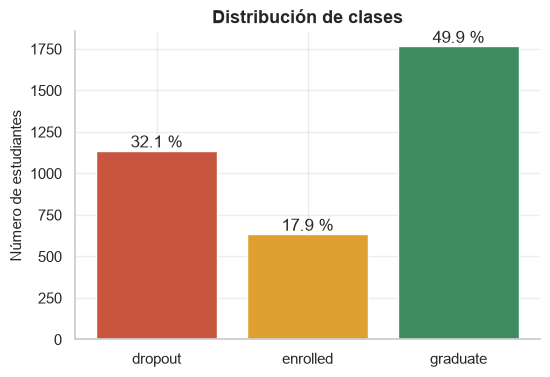

In [8]:
conteo = y.value_counts()[CLASES]
porcentaje = conteo / conteo.sum() * 100
colores = [COLORES_CLASE[c] for c in CLASES]

plt.figure(figsize=(6, 4))
plt.bar(CLASES, conteo, color=colores)
for i in range(len(CLASES)):
    plt.text(i, conteo.iloc[i] + 20, f"{porcentaje.iloc[i]:.1f} %", ha="center")
plt.title("Distribución de clases")
plt.ylabel("Número de estudiantes")
mostrar("2_2_distribucion_clases")

**Qué hace el código.**

- Cuenta los estudiantes de cada clase y calcula su porcentaje.
- Dibuja una barra por clase, con su color, y escribe el porcentaje encima de cada barra.
- Guarda la figura en `Images/2_2_distribucion_clases.png`.

---

### 2.3 Tipo de cada atributo

La tabla muestra, para cada uno de los 30 atributos del 1er semestre, su tipo, cuántos valores distintos toma y su rango. Hay que fijarse en que los **nominales** tienen valores como 9991 o 195: son códigos, no cantidades (el significado de cada código está en la ficha de UCI).

In [9]:
tipos = []
for c in cols_1er:
    if c in NOMINALES:
        tipo = "nominal"
    elif c in BINARIOS:
        tipo = "binario"
    elif c in ORDINALES:
        tipo = "ordinal"
    else:
        tipo = "numérico"
    tipos.append([c, tipo, X[c].nunique(), X[c].min(), X[c].max()])

tabla_tipos = pd.DataFrame(tipos, columns=["atributo", "tipo", "valores distintos", "mínimo", "máximo"])
tabla_tipos

,atributo,tipo,valores distintos,mínimo,máximo
0,Marital status,nominal,6,1.0000,6.0000
1,Application mode,nominal,17,1.0000,57.0000
2,Application order,ordinal,8,0.0000,9.0000
3,Course,nominal,17,33.0000,9991.0000
4,Daytime/evening attendance,binario,2,0.0000,1.0000
5,Previous qualification,nominal,17,1.0000,43.0000
6,Previous qualification (grade),numérico,100,95.0000,190.0000
7,Nacionality,nominal,18,1.0000,109.0000
8,Mother's qualification,nominal,26,1.0000,44.0000
9,Father's qualification,nominal,32,1.0000,44.0000


**Qué hace el código.**

- Recorre los 30 atributos del 1er semestre y les asigna su tipo según la lista a la que pertenecen (sección 1.6).
- Para cada uno calcula cuántos valores distintos toma, su mínimo y su máximo, y lo reúne en `tabla_tipos`.

---

### 2.4 Categorías de los atributos nominales

Varios nominales tienen muchas categorías con muy pocos estudiantes. Por ejemplo, la ocupación del padre tiene 45 códigos y 33 de ellos tienen menos de 30 casos; la nacionalidad tiene 18 códigos, pero el 97.3 % de los estudiantes son portugueses.

**Consecuencia para el preprocesamiento:** al aplicar one-hot, las categorías raras se agrupan en una sola columna (`min_frequency=30`). Así se evita crear decenas de columnas casi vacías que solo agregan ruido.

In [10]:
filas = []
for c in NOMINALES:
    conteo_cat = X[c].value_counts()
    raras = (conteo_cat < 30).sum()
    dominante = conteo_cat.iloc[0] / len(X) * 100
    filas.append([c, len(conteo_cat), raras, dominante])

tabla_nom = pd.DataFrame(filas, columns=["atributo", "categorías", "categorías con < 30 casos", "% de la más común"])
tabla_nom.sort_values("categorías", ascending=False)

,atributo,categorías,categorías con < 30 casos,% de la más común
8,Father's occupation,45,33,23.0574
6,Father's qualification,32,23,27.1546
7,Mother's occupation,31,21,35.6598
5,Mother's qualification,26,17,23.9898
4,Nacionality,18,16,97.3156
1,Application mode,17,7,38.8810
3,Previous qualification,17,10,83.8090
2,Course,17,1,17.3778
0,Marital status,6,3,88.4431


**Qué hace el código.**

- Para cada atributo nominal cuenta cuántas categorías tiene, cuántas tienen menos de 30 estudiantes (las que `min_frequency=30` agrupará en el one-hot) y qué porcentaje de los estudiantes ocupa la categoría más común.
- Muestra la tabla ordenada de mayor a menor número de categorías.

---

### 2.5 Atributos binarios más relacionados con la clase

Cada barra muestra cómo se reparten las clases según el valor del atributo (0 = no, 1 = sí):

- **Colegiatura al día:** quien **no** está al día deserta en cerca del 87 % de los casos, contra 25 % de quien sí lo está. Es la señal no académica más fuerte.
- **Becado:** los becados se gradúan mucho más (≈76 % contra ≈41 %).
- **Deudor:** los deudores desertan más del doble (≈63 % contra ≈28 %).
- **Género (1 = hombre):** los hombres desertan más (≈46 % contra ≈25 %). Probablemente se mezcla con la carrera, porque hay carreras con mayoría de hombres y más deserción.

La situación económica pesa mucho en la deserción.

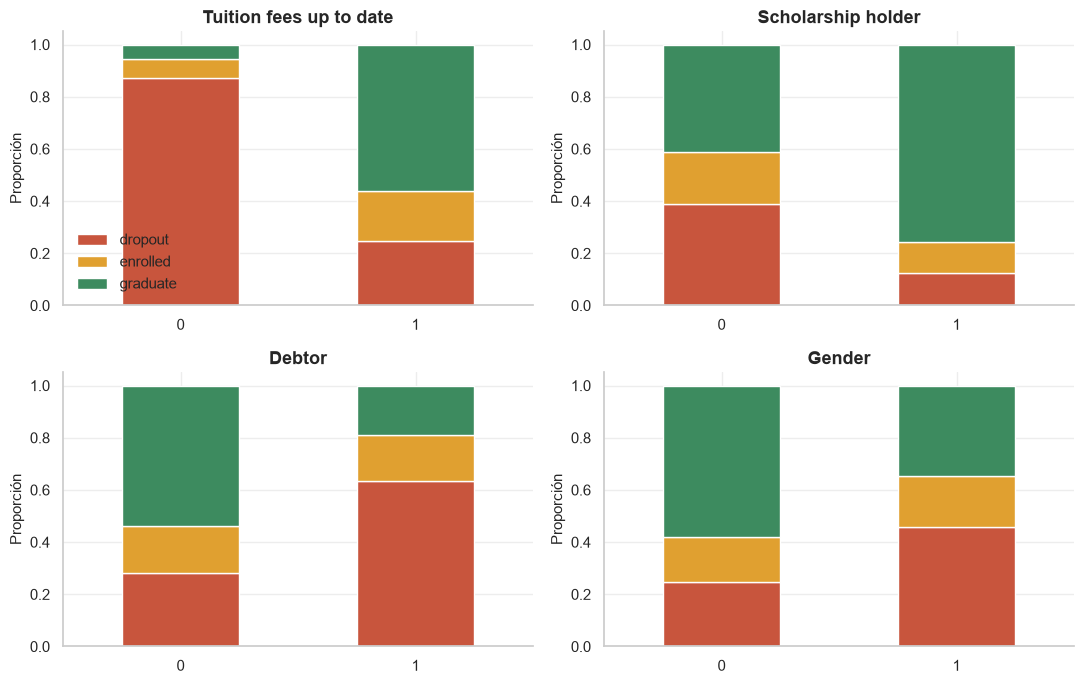

In [11]:
importantes = ["Tuition fees up to date", "Scholarship holder", "Debtor", "Gender"]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, c in zip(axes.flatten(), importantes):
    tabla = pd.crosstab(X[c], y, normalize="index")[CLASES]
    tabla.plot(kind="bar", stacked=True, color=colores, ax=ax, legend=False, rot=0)
    ax.set_title(c)
    ax.set_xlabel("")
    ax.set_ylabel("Proporción")
axes[0, 0].legend(loc="lower left")
plt.tight_layout()
mostrar("2_5_binarios_vs_clase")

**Qué hace el código.**

- Para cuatro atributos binarios calcula con `pd.crosstab(..., normalize="index")` la proporción de cada clase entre los estudiantes con valor 0 y entre los que tienen valor 1.
- Dibuja esas proporciones como barras apiladas en una malla de 2×2, con la leyenda en el primer panel.
- Guarda la figura en `Images/2_5_binarios_vs_clase.png`.

---

### 2.6 Atributos numéricos más relacionados con la clase

- **Unidades aprobadas y nota del 1er semestre:** son los atributos más importantes. Los desertores aprueban muy pocas materias, los *enrolled* quedan en medio y los graduados aprueban más.
- **Nota = 0 no es una calificación:** significa que el estudiante no aprobó ninguna materia. La tabla de abajo muestra que el 79 % de esos estudiantes deserta.
- **Edad:** los desertores ingresan con más edad (posiblemente trabajan o retoman sus estudios).
- **Nota de admisión:** las diferencias entre clases son pequeñas.

También se ve que ***enrolled* se parece a las otras dos clases**: está en medio en casi todo. Por eso será la clase más difícil de predecir.

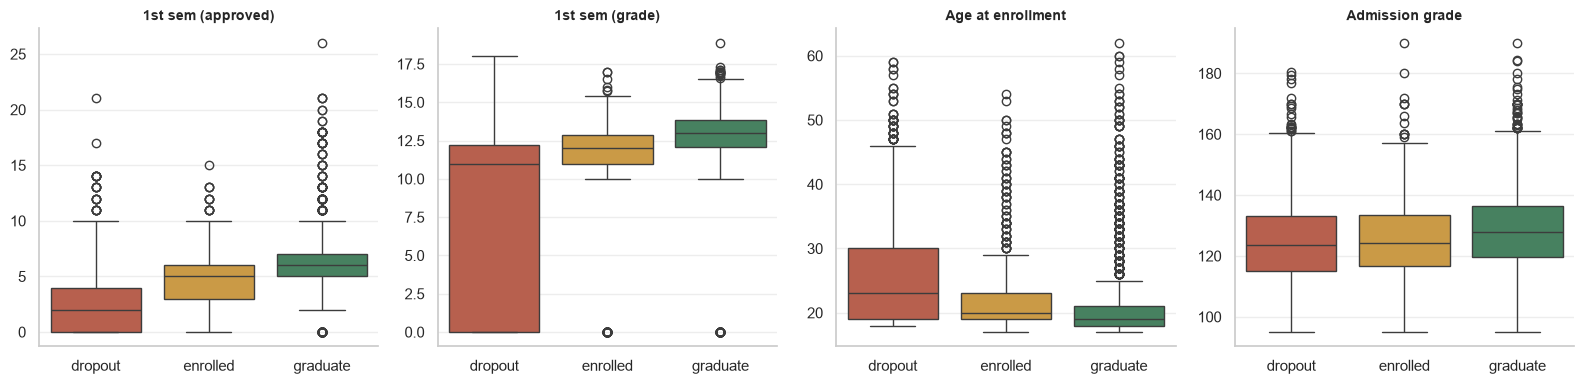

Target,dropout,enrolled,graduate
Curricular units 1st sem (approved),,,
False,23.2065,19.4678,57.3257
True,78.5965,10.0000,11.4035


In [12]:
numericos_clave = ["Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
                   "Age at enrollment", "Admission grade"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, numericos_clave):
    sns.boxplot(x=y, y=X[c], order=CLASES, hue=y, palette=COLORES_CLASE, legend=False, ax=ax)
    ax.set_title(c.replace("Curricular units ", ""), fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
mostrar("2_6_numericos_vs_clase")

# Estudiantes que no aprobaron ninguna materia en el 1er semestre (True) contra el resto (False)
sin_aprobar = X["Curricular units 1st sem (approved)"] == 0
pd.crosstab(sin_aprobar, y, normalize="index")[CLASES] * 100

**Qué hace el código.**

- Dibuja un diagrama de caja por clase para cuatro atributos numéricos.
- Después marca a los estudiantes que no aprobaron ninguna materia en el 1er semestre y muestra el porcentaje de cada clase en ese grupo (`True`) y en el resto (`False`).
- Guarda la figura en `Images/2_6_numericos_vs_clase.png`.

---

### 2.7 Información disponible al decidir: 1er vs. 2º semestre

El modelo solo usa lo que se conoce al cierre del 1er semestre. Las 6 columnas del 2º semestre quedan fuera.

La tabla compara cada columna del 1er semestre con su par del 2º. Las correlaciones son altas en materias acreditadas (0.94), inscritas (0.94) y aprobadas (0.91), y menores en evaluaciones (0.78), nota (0.84) y materias sin evaluación (0.55). En buena parte, **lo que pasa en el 2º semestre se parece a lo que ya se vio en el 1º**. La hipótesis es que esperar un semestre más mejoraría el modelo, pero no por mucho; aun así, la parte que no está correlacionada podría aportar información nueva, sobre todo para distinguir a los *enrolled*. Se medirá al final con validación cruzada.

In [13]:
pares = []
for c2 in cols_2do:
    c1 = c2.replace("2nd sem", "1st sem")
    nombre = c1.replace("Curricular units 1st sem ", "")
    pares.append([nombre, X2[c1].corr(X2[c2])])

pd.DataFrame(pares, columns=["unidades curriculares", "correlación 1er vs 2º semestre"])

,unidades curriculares,correlación 1er vs 2º semestre
0,(credited),0.9437
1,(enrolled),0.9423
2,(evaluations),0.7817
3,(approved),0.9058
4,(grade),0.8373
5,(without evaluations),0.5515


**Qué hace el código.**

- Para cada columna del 2º semestre busca su par del 1er semestre (cambiando `2nd sem` por `1st sem` en el nombre) y calcula la correlación de Pearson entre ambas, usando `X2`.
- Muestra las seis correlaciones en una tabla.

---

### 2.8 Falsas magnitudes en los atributos nominales

Los nominales vienen como números (`Course` = 33, 171, …, 9991), pero son **códigos**: que 9991 sea mayor que 9003 no significa nada. Si un modelo los usara como cantidades, supondría que la deserción sube o baja de forma ordenada con el código.

La gráfica ordena los códigos de menor a mayor (solo las categorías con 30 estudiantes o más) y muestra el % de desertores de cada uno. Si el código fuera una magnitud, la línea subiría o bajaría de forma más o menos constante. En cambio, sube y baja sin patrón, y la correlación de Spearman entre el código y la tasa de deserción es casi nula (0.07 en `Course` y −0.18 en `Application mode`). Por ejemplo, las carreras 9119 y 9130 tienen ≈ 56 % de desertores, pero la 9238, apenas dos lugares después en el orden de códigos, solo ≈ 19 %, y la 9500 ≈ 15 %.

**Consecuencia para el preprocesamiento:** en la regresión logística, el SVM y kNN, los nominales se pasan a one-hot (sección 4.2), para que cada categoría tenga su propio coeficiente o su propia dimensión en vez de una posición arbitraria en una recta.

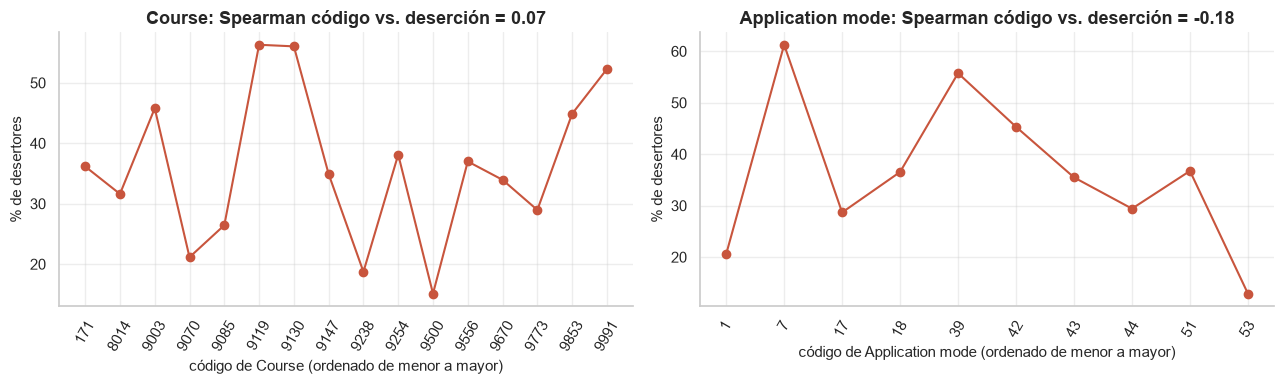

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, c in zip(axes, ["Course", "Application mode"]):
    n = X[c].value_counts()
    codigos = sorted(n[n >= 30].index)
    tasa = pd.crosstab(X[c], y, normalize="index").loc[codigos, "dropout"] * 100
    rho = pd.Series(codigos).corr(pd.Series(tasa.values), method="spearman")

    ax.plot(range(len(codigos)), tasa.values, color=COLORES_CLASE["dropout"], marker="o")
    ax.set_xticks(range(len(codigos)))
    ax.set_xticklabels(codigos, rotation=60)
    ax.set_xlabel(f"código de {c} (ordenado de menor a mayor)")
    ax.set_ylabel("% de desertores")
    ax.set_title(f"{c}: Spearman código vs. deserción = {rho:.2f}")
plt.tight_layout()
mostrar("2_8_falsas_magnitudes_nominales")

**Qué hace el código.**

- Para `Course` y `Application mode` toma solo los códigos con 30 estudiantes o más y los ordena de menor a mayor.
- Calcula el porcentaje de desertores de cada código y la correlación de Spearman entre el código y ese porcentaje.
- Grafica el porcentaje de desertores siguiendo el orden de los códigos; el título de cada panel muestra la correlación.
- Guarda la figura en `Images/2_8_falsas_magnitudes_nominales.png`.

---

### 2.9 Escalas distintas en los atributos numéricos

Los 12 numéricos y el ordinal tienen escalas muy distintas: las notas van de 95 a 190 (desviación ≈ 14), mientras que las materias sin evaluación van de 0 a 12 (desviación ≈ 0.7).

Esto importa en los modelos que usan distancias. Para dos estudiantes tomados al azar, cada atributo aporta en promedio 2·varianza a la distancia euclidiana al cuadrado, así que su **porcentaje de la distancia** es su varianza entre la suma de las varianzas. La tabla y la gráfica lo muestran:

- **Escala original:** la nota de admisión (≈ 40 %) y la nota previa (≈ 33 %) deciden casi tres cuartas partes de la distancia, y la edad otro ≈ 11 %. Las materias aprobadas y la nota del 1er semestre, que son los atributos más relacionados con la clase (ver 2.6), juntas aportan solo ≈ 6 %. Para un kNN sin escalar, dos estudiantes serían "parecidos" si tienen notas de admisión parecidas, aunque uno haya aprobado todo y el otro nada. Con la distancia Manhattan el efecto es el mismo, porque también suma las diferencias sin escalar.
- **Después de `StandardScaler`:** cada atributo aporta lo mismo (1/13 ≈ 7.7 %, la línea punteada).

**Consecuencia para el preprocesamiento:** kNN, el SVM y la regresión logística escalan los numéricos (sección 4.2). El árbol no lo necesita, porque cada corte usa un solo atributo a la vez.

*Nota:* aquí `StandardScaler` se ajusta con todo `X` solo para ilustrar su efecto; no se evalúa ningún modelo, así que no hay fuga de información. En los modelos, el escalado va dentro del `Pipeline` (sección 4.1).

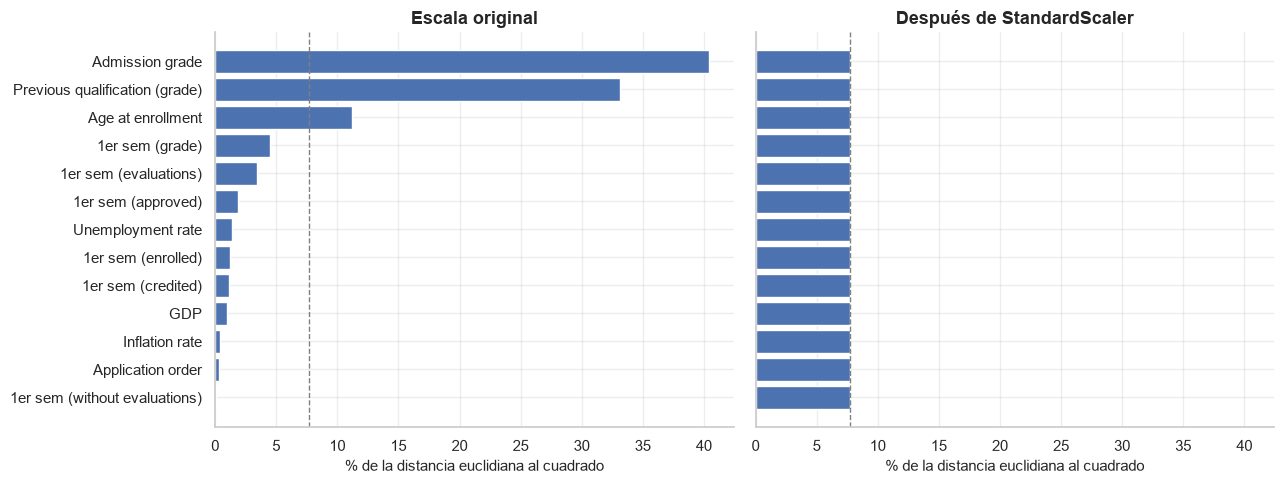

,mínimo,máximo,desv. estándar,% de la distancia (original),% de la distancia (estandarizado)
Admission grade,95.0000,190.0000,14.4861,40.4107,7.6923
Previous qualification (grade),95.0000,190.0000,13.1222,33.1596,7.6923
Age at enrollment,17.0000,62.0000,7.6223,11.1883,7.6923
Curricular units 1st sem (grade),0.0000,18.8750,4.8333,4.4987,7.6923
Curricular units 1st sem (evaluations),0.0000,45.0000,4.1997,3.3965,7.6923
Curricular units 1st sem (approved),0.0000,26.0000,3.1200,1.8745,7.6923
Unemployment rate,7.6000,16.2000,2.6513,1.3536,7.6923
Curricular units 1st sem (enrolled),0.0000,26.0000,2.5058,1.2092,7.6923
Curricular units 1st sem (credited),0.0000,20.0000,2.4168,1.1248,7.6923
GDP,-4.0600,3.5100,2.2701,0.9924,7.6923


In [15]:
from sklearn.preprocessing import StandardScaler

CONT = NUMERICOS + ORDINALES

escalas = pd.DataFrame({
    "mínimo": X[CONT].min(),
    "máximo": X[CONT].max(),
    "desv. estándar": X[CONT].std(),
    "% de la distancia (original)": X[CONT].var() / X[CONT].var().sum() * 100,
}).sort_values("% de la distancia (original)", ascending=False)

X_est = pd.DataFrame(StandardScaler().fit_transform(X[CONT]), columns=CONT)
escalas["% de la distancia (estandarizado)"] = (X_est.var() / X_est.var().sum() * 100)[escalas.index]

nombres_cortos = [c.replace("Curricular units 1st sem ", "1er sem ") for c in escalas.index]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, col, titulo in zip(axes,
                           ["% de la distancia (original)", "% de la distancia (estandarizado)"],
                           ["Escala original", "Después de StandardScaler"]):
    ax.barh(nombres_cortos, escalas[col], color="C0")
    ax.axvline(100 / len(CONT), color="gray", ls="--", lw=1)
    ax.set_xlabel("% de la distancia euclidiana al cuadrado")
    ax.set_title(titulo)
axes[0].invert_yaxis()
plt.tight_layout()
mostrar("2_9_escalas_numericos")

escalas

**Qué hace el código.**

- Para los 13 atributos continuos (`CONT`, los numéricos más el ordinal) calcula el mínimo, el máximo, la desviación estándar y el porcentaje de la distancia: la varianza de cada atributo entre la suma de las varianzas.
- Repite el porcentaje después de estandarizar con `StandardScaler` (`X_est`).
- Grafica ambos porcentajes lado a lado con el mismo eje horizontal; la línea punteada marca el reparto igualitario (1/13).
- Muestra la tabla `escalas`, ordenada por el peso de cada atributo en la escala original.
- Guarda la figura en `Images/2_9_escalas_numericos.png`.

---

## 3. Protocolo de evaluación

Los cinco clasificadores se optimizan y comparan con **validación cruzada estratificada de 5 pliegues** sobre el conjunto de entrenamiento:

- **Estratificada:** cada pliegue conserva la proporción de clases del conjunto completo (≈32 % dropout, ≈18 % enrolled, ≈50 % graduate). Sin estratificar, un pliegue podría quedarse con pocos *enrolled* y su F1 sería poco confiable.
- **5 pliegues y no 10:** con 5, cada pliegue de validación tiene 127 *enrolled*; con 10 tendría ~63, y el F1 de esa clase variaría mucho entre pliegues solo por azar. Además, cada búsqueda evalúa 50 o más configuraciones, y con 10 pliegues el tiempo se duplicaría (sobre todo en el SVM). A cambio, cada modelo entrena con el 80 % de los datos en lugar del 90 %, una diferencia pequeña con 3539 estudiantes.
- **Barajados (`shuffle=True`):** los `id` del entrenamiento van en orden (1, 2, 3…). Si ese orden sigue la generación de ingreso, sin barajar cada pliegue sería un bloque de años consecutivos. Barajar con `random_state=SEED` evita ese efecto y mantiene la reproducibilidad.
- **Los mismos pliegues para los cinco modelos:** los pliegues se generan una sola vez con `SEED` y se guardan en `PLIEGUES`. Así, las diferencias entre clasificadores se deben al modelo y no a cómo se repartieron los estudiantes. Como `X2` tiene los mismos estudiantes en el mismo orden, los mismos `PLIEGUES` se usan también para medir cuánto aporta el 2º semestre.
- **Métrica:** `METRICA = "f1_macro"`, el promedio del F1 de las tres clases. Se usa en todas las búsquedas.

La tabla comprueba que la estratificación funcionó: cada pliegue de validación tiene ~708 estudiantes con la misma proporción de clases.

In [16]:
from sklearn.model_selection import StratifiedKFold

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
PLIEGUES = list(CV.split(X, y))
METRICA = "f1_macro"

# Comprobación: estudiantes de cada clase en cada pliegue de validación
filas = []
for i, (idx_entr, idx_val) in enumerate(PLIEGUES):
    conteo_val = y.iloc[idx_val].value_counts()
    filas.append([i + 1, len(idx_entr), len(idx_val),
                  conteo_val["dropout"], conteo_val["enrolled"], conteo_val["graduate"]])

tabla_pliegues = pd.DataFrame(filas, columns=["pliegue", "entrenamiento", "validación",
                                              "dropout", "enrolled", "graduate"])
tabla_pliegues

,pliegue,entrenamiento,validación,dropout,enrolled,graduate
0,1,2831,708,227,127,354
1,2,2831,708,227,127,354
2,3,2831,708,228,127,353
3,4,2831,708,228,127,353
4,5,2832,707,227,127,353


**Qué hace el código.**

- Crea un `StratifiedKFold` de 5 pliegues, barajado con `SEED`, y guarda los índices en `PLIEGUES` para que los cinco modelos usen exactamente las mismas particiones.
- Define la métrica `METRICA = "f1_macro"`.
- Cuenta cuántos estudiantes de cada clase quedan en el entrenamiento y la validación de cada pliegue, para comprobar la estratificación.

---

## 4. Preprocesamiento por clasificador

### 4.1 Por qué todo va dentro de un `Pipeline`

Varios pasos del preprocesamiento **aprenden algo de los datos**: `StandardScaler` calcula la media y la desviación de cada columna, `min_frequency` decide qué categorías son raras y `KBinsDiscretizer` calcula los cortes de los intervalos. Si estos pasos se ajustaran con los 3539 estudiantes antes de la validación cruzada, el pliegue de validación ya habría "visto" su propia información y el F1 saldría optimista (**fuga de información**).

Dentro de un `Pipeline`, cada pliegue reajusta el preprocesamiento solo con su 80 % de entrenamiento y lo aplica al 20 % de validación, igual que pasará con el modelo final y el conjunto de prueba. Cada `Pipeline` usa un `ColumnTransformer` que trata por separado los cuatro grupos de atributos de la sección 1.6.

---

### 4.2 Preprocesamiento de cada modelo

Para decidirlo se hacen tres preguntas por modelo: ¿usa distancias o productos punto (y entonces le importan las escalas, ver 2.9)?, ¿trataría el código 9991 de `Course` como "mayor" que el 33 (y entonces necesita one-hot, ver 2.8)?, y ¿qué distribución supone sobre cada atributo?

| Modelo | Nominales (9) | Numéricos (12) y ordinal (1) | Binarios (8) | ¿Por qué? |
|---|---|---|---|---|
| **Regresión logística** | One-hot, agrupando las raras (`min_frequency=30`) | `StandardScaler` | 0/1 sin cambios | Calcula un producto punto **w·x**. Con el código tal cual, un solo coeficiente multiplicaría 9991, como si la carrera fuera una cantidad; el one-hot le da un coeficiente propio a cada carrera. Escalar hace que la regularización (L1/L2) castigue a todos los coeficientes por igual; sin escalar, penaliza injustamente a los atributos con números pequeños, que necesitan coeficientes más grandes. |
| **SVM** | One-hot (`min_frequency=30`) | `StandardScaler` | 0/1 sin cambios | El kernel lineal usa productos punto y el RBF usa distancias: en ambos casos comparar 9991 contra 33 no tiene sentido, y las columnas con números grandes (nota de admisión, 95–190) dominarían a las pequeñas (materias aprobadas, 0–26). Además, `gamma` y `C` solo tienen una interpretación razonable con datos escalados. |
| **kNN** | One-hot (`min_frequency=30`) | `StandardScaler` o `MinMaxScaler` (se elige en la búsqueda) | 0/1 sin cambios | Es el modelo más sensible: todo son distancias. Sin one-hot, la carrera 9991 quedaría "lejísimos" de la 33 y "cerca" de la 9853 sin ninguna razón. Sin escalar, la distancia la decidiría casi solo la nota de admisión. Cada columna one-hot suma una dimensión y kNN empeora con muchas, así que agrupar las categorías raras le ayuda más que a nadie. |
| **Árbol de decisión** | Código entero tal cual | Sin cambios | Sin cambios | No usa distancias ni productos punto: hace preguntas de corte ("¿aprobadas ≤ 3?"), y escalar no cambia ningún corte. Con el código entero hace cortes como "¿Course ≤ 9200?", que agrupan carreras en un orden arbitrario; puede repetir cortes para aislar una carrera, pero gasta profundidad en hacerlo. El one-hot, en cambio, obliga a una pregunta por cada carrera y fragmenta los datos. |
| **Naive Bayes** | Ver 4.3 | Ver 4.3 | Ver 4.3 | La variante es un hiperparámetro y cada variante necesita su propio preprocesamiento. |

La tabla resume las decisiones. Cómo funciona cada modelo, y por qué de su funcionamiento sale su preprocesamiento, se explica con más detalle al inicio de cada subsección de la sección 5 (5.1 a 5.5).

**Binarios.** Ya están en 0/1, así que se dejan sin cambios (`"passthrough"`). En kNN esto implica que pesan algo menos en la distancia que un numérico estandarizado (que varía aproximadamente entre −3 y +3). Por eso en kNN se prueba también `MinMaxScaler`, que deja los numéricos en [0, 1], en igualdad con los binarios.

**Ordinal.** `Application order` (0 = primera opción) conserva su orden como número y recibe el mismo tratamiento que los numéricos.

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler

CONTINUOS = NUMERICOS + ORDINALES

def one_hot():
    """Onehot agrupa las categorias raras y manda ahi las desconocidas""" 
    return OneHotEncoder(
        min_frequency=30, 
        handle_unknown="infrequent_if_exist", 
        sparse_output=False
    )

def prep_escalado(escalador=None):
    """Preprocesamiento de regresion logistica, SVM y kNN"""
    if escalador is None:
        escalador = StandardScaler()
    return ColumnTransformer([
        ("nominales", one_hot(), NOMINALES),
        ("continuos", escalador, CONTINUOS),
        ("binarios", "passthrough", BINARIOS),
    ])

**Qué hace el código.**

- `one_hot()` crea un `OneHotEncoder` que agrupa en una sola columna las categorías con menos de 30 casos, manda ahí las categorías que no vio al entrenar y devuelve una matriz densa.
- `prep_escalado(escalador)` arma el `ColumnTransformer` de la regresión logística, el SVM y kNN: one-hot a los nominales, el escalador indicado (por defecto `StandardScaler`) a los numéricos y al ordinal, y los binarios sin cambios.
- Son funciones y no objetos para que cada pipeline reciba transformadores nuevos, sin ajustar.

---

### 4.3 Naive Bayes: dos variantes, dos preprocesamientos

| Variante | Nominales y binarios | Numéricos y ordinal | Suavizado |
|---|---|---|---|
| **`CategoricalNB`** | Recodificados a enteros 0, 1, 2… (`OrdinalEncoder`) | Discretizados en intervalos por cuantiles (`KBinsDiscretizer`, `encode="ordinal"`) | `alpha` |
| **`GaussianNB`** | One-hot | Sin cambios | `var_smoothing` |

`CategoricalNB` estima P(valor | clase) **contando**, lo cual es natural para nominales y binarios; los numéricos se discretizan para poder contarlos. El número de intervalos (`n_bins`) es otro hiperparámetro de la búsqueda.

`GaussianNB` supone que cada atributo sigue una campana dentro de cada clase, y en estos datos eso falla: los nominales son códigos, `Curricular units 1st sem (approved)` tiene un pico en 0 (el 16 % de los estudiantes no aprobó ninguna materia) y `Curricular units 1st sem (credited)` vale 0 en el 86 % de los casos. Aun así se incluye en la búsqueda para comprobarlo con datos y no solo con el argumento. Escalar no le cambia nada, porque estima la media y la varianza de cada atributo por clase.

In [18]:
from sklearn.preprocessing import OrdinalEncoder, KBinsDiscretizer

CATEGORICAS = [sorted(set(des_train[c]) | set(des_test[c])) for c in NOMINALES]

def prep_categorico(n_bins=5):
    """Preprocesamiento de CategoricalNB: todo a enteros 0, 1, 2..."""
    return ColumnTransformer([
        ("nominales", OrdinalEncoder(categories=CATEGORICAS), NOMINALES),
        ("binarios", "passthrough", BINARIOS),
        ("continuos", KBinsDiscretizer(n_bins, encode="ordinal", strategy="quantile"), CONTINUOS)
    ])

def min_categorias(n_bins=5):
    """Numero de categorias de cada columna, en el mismo orden que prep_categorico"""
    return [len(c) for c in CATEGORICAS] + [2] * len(BINARIOS) + [n_bins] * len(CONTINUOS)

prep_gaussiano = ColumnTransformer([
    ("nominales", one_hot(), NOMINALES),
    ("resto", "passthrough", BINARIOS + CONTINUOS),
])

**Qué hace el código.**

- `CATEGORICAS` guarda todos los códigos posibles de cada nominal (los que aparecen en entrenamiento o en prueba; solo usa los atributos, no `Target`).
- `prep_categorico(n_bins)` arma el `ColumnTransformer` de `CategoricalNB`: nominales a enteros con `OrdinalEncoder`, binarios sin cambios y continuos discretizados en `n_bins` intervalos por cuantiles.
- `min_categorias(n_bins)` devuelve el número de categorías de cada columna, en el mismo orden, para el parámetro `min_categories` de `CategoricalNB`.
- `prep_gaussiano` aplica one-hot a los nominales y deja el resto sin cambios, para `GaussianNB`.

---

### 4.4 Categorías que el modelo no vio al entrenar

El conjunto de prueba trae códigos que **no aparecen en el entrenamiento**: 3 de `Nacionality` (13, 14, 32), 3 de `Mother's qualification`, 2 de `Father's qualification` y uno en `Application mode`, `Mother's occupation` y `Father's occupation`. Lo mismo ocurre dentro de la validación cruzada: `Father's occupation` tiene 17 códigos con un solo estudiante, y cuando ese estudiante cae en el pliegue de validación, el modelo de ese pliegue nunca vio su código.

Si no se maneja, el modelo se detiene con un error al encontrar un código desconocido. Cada familia de modelos lo resuelve distinto:

- **One-hot (regresión logística, SVM, kNN y `GaussianNB`):** con `handle_unknown="infrequent_if_exist"`, un código desconocido cae en la misma columna que las categorías raras. Es coherente con `min_frequency=30`: un código que nunca se vio es, por definición, infrecuente.
- **`CategoricalNB`:** `OrdinalEncoder` no puede mandar los desconocidos a "raras", y `CategoricalNB` falla si recibe un índice de categoría que no vio al entrenar. Por eso se combinan dos piezas:
  - `CATEGORICAS` le da al encoder **la lista de todos los códigos posibles** de cada nominal, así que ningún código es desconocido. Se arma con los valores que aparecen en entrenamiento o en prueba; solo usa los atributos, **nunca `Target`**, y esos códigos son los mismos que lista el diccionario del dataset en UCI.
  - `min_categorias` le dice a `CategoricalNB` cuántas categorías tiene cada columna, aunque alguna no aparezca en el entrenamiento de un pliegue.

  Un código que no apareció al entrenar queda con conteo 0, y el suavizado `alpha` le asigna una probabilidad pequeña pero distinta de cero. Esa es justamente la función del suavizado de Laplace.

**Aviso de `KBinsDiscretizer`.** En atributos con muchos valores repetidos (por ejemplo, `credited` vale 0 en el 86 % de los casos), varios cuantiles coinciden y `KBinsDiscretizer` elimina los intervalos vacíos con un aviso. Es esperado y no afecta al modelo, así que se filtra solo ese mensaje; los demás avisos se siguen mostrando.

---

### 4.5 Comprobación y F1 de referencia

La celda siguiente evalúa cada pipeline con sus hiperparámetros por defecto, con los mismos `PLIEGUES`. Sirve para dos cosas: comprobar que ningún pipeline falla por categorías desconocidas en ningún pliegue, y tener un **punto de partida** contra el cual medir cuánto mejora cada modelo con la optimización de la sección 5.

In [19]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

warnings.filterwarnings("ignore", message="Bins whose width are too small")

pipes_base = {
    "Regresion logistica": Pipeline([("prep", prep_escalado()),
    ("modelo", LogisticRegression(max_iter=2000, random_state=SEED))]),
    "Arbol de decision": Pipeline([("modelo", DecisionTreeClassifier(random_state=SEED))]),
    "Naive Bayes (categorico)": Pipeline([("prep", prep_categorico()), ("modelo", CategoricalNB(min_categories=min_categorias()))]),
    "Naive Bayes (Gaussiano)": Pipeline([("prep", prep_gaussiano), ("modelo", GaussianNB())]),
    "kNN": Pipeline([("prep", prep_escalado()), ("modelo", KNeighborsClassifier())]),
    "SVM": Pipeline([("prep", prep_escalado()), ("modelo", SVC(random_state=SEED))]),
}

filas = []
for nombre, pipe in pipes_base.items():
    inicio = time.perf_counter()
    f1 = cross_val_score(pipe, X, y, cv=PLIEGUES, scoring=METRICA)
    filas.append([nombre, f1.mean(), f1.std(), time.perf_counter() - inicio])

tabla_base = pd.DataFrame(filas, columns=["modelo", "F1 macro (media)", "F1 macro (desv.)", "tiempo (s)"])
tabla_base.sort_values("F1 macro (media)", ascending=False)

,modelo,F1 macro (media),F1 macro (desv.),tiempo (s)
0,Regresion logistica,0.6576,0.0203,0.5835
5,SVM,0.6402,0.0085,2.5359
2,Naive Bayes (categorico),0.6155,0.0089,0.2910
1,Arbol de decision,0.5890,0.0136,0.1558
4,kNN,0.5675,0.0090,0.2310
3,Naive Bayes (Gaussiano),0.3709,0.0658,0.1475


**Qué hace el código.**

- Importa los cinco clasificadores y filtra solo el aviso de `KBinsDiscretizer` sobre intervalos vacíos.
- Arma un pipeline por modelo con sus hiperparámetros por defecto (Naive Bayes en sus dos variantes).
- Evalúa cada uno con `cross_val_score` sobre los mismos `PLIEGUES` y reúne en `tabla_base` la media y la desviación del F1 macro y el tiempo.

**Lectura.** Sin optimizar, la regresión logística (F1 macro ≈ 0.658) y el SVM (≈ 0.640) quedan arriba; los dos usan one-hot y escalado. Le siguen `CategoricalNB` (≈ 0.616), el árbol (≈ 0.589) y kNN (≈ 0.568). Ninguno falló por categorías desconocidas.

`GaussianNB` queda muy por debajo (≈ 0.371) y es además el más inestable entre pliegues (desviación ≈ 0.066, contra ≈ 0.01–0.02 de los demás). Esto confirma con datos el argumento de la sección 4.3: suponer una campana por atributo no funciona con códigos nominales ni con atributos llenos de ceros. Aun así se mantiene como opción en la búsqueda de Naive Bayes, para que la elección de la variante la decida la validación cruzada.

Las diferencias entre modelos todavía no son definitivas: el árbol sin límite de profundidad sobreajusta, kNN usa k = 5 sin ponderar y el SVM usa C y gamma por defecto. La sección 5 lleva cada uno a su mejor versión.

---

## 5. Optimización de hiperparámetros

### 5.0 Método

Los hiperparámetros de cada clasificador se buscan con **Optuna**, que usa un muestreador bayesiano (TPE): las primeras configuraciones son aleatorias y después se concentra en las zonas del espacio que dieron mejor F1. Esto permite llegar a la meseta con unas 100 configuraciones, y maneja bien los espacios **condicionales** (por ejemplo, `gamma` solo existe si el kernel del SVM no es lineal, y cada variante de Naive Bayes tiene su propio preprocesamiento).

Reglas comunes a los cinco clasificadores:

- **Mismos pliegues:** cada configuración se evalúa con `cross_val_score(..., cv=PLIEGUES, scoring=METRICA)`, es decir, con los mismos 5 pliegues estratificados de la sección 3 y el F1 macro como objetivo.
- **Reproducibilidad:** el muestreador usa `TPESampler(seed=SEED)`, así que la secuencia de configuraciones es la misma en cada ejecución.
- **Número de configuraciones:** se declara en cada subsección y nunca es menor a 50.
- **Escala logarítmica** para los hiperparámetros que actúan por órdenes de magnitud (`C`, `gamma`, `alpha`, `var_smoothing`, `ccp_alpha`): pasar de 0.01 a 0.1 cambia el modelo tanto como pasar de 10 a 100. En escala lineal, casi todas las pruebas caerían en la década más alta y los valores pequeños casi no se explorarían. Los conteos (profundidad, k, número de intervalos) usan escala lineal.

Dos funciones evitan repetir el mismo código cinco veces:

- `optimizar(nombre, crear_pipeline, n_trials)`: ejecuta la búsqueda, mide su tiempo y guarda en `resultados` el estudio, el tiempo y la función que arma el pipeline (se usan en la sección 6). En cada configuración guarda también los 5 F1 de los pliegues, para reportar la desviación estándar sin recalcular nada.
- `grafica_meseta(nombre, param, separar_por)`: a la izquierda, el **mejor F1 macro alcanzado contra el número de configuraciones evaluadas**; a la derecha, el F1 de cada configuración contra el hiperparámetro más influyente. La primera muestra si la búsqueda llegó a una meseta; la segunda, por qué.

In [20]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

resultados = {}

def optimizar(nombre, crear_pipeline, n_trials):
    """Busca los hiperparametros de un modelo con Optuna y validacion cruzada"""

    def objetivo(trial):
        pipe = crear_pipeline(trial)
        f1 = cross_val_score(pipe, X, y, cv=PLIEGUES, scoring=METRICA, n_jobs=-1)
        trial.set_user_attr("f1_pliegues", f1.tolist())
        return f1.mean()

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))

    inicio = time.perf_counter()
    study.optimize(objetivo, n_trials=n_trials)
    tiempo = time.perf_counter() - inicio

    resultados[nombre] = {"study": study, "tiempo": tiempo, "crear_pipeline": crear_pipeline}
    f1_mejor = study.best_trial.user_attrs["f1_pliegues"]
    print(f"{nombre}: {n_trials} configuraciones en {tiempo:.0f} s")
    print(f"Mejor F1 macro: {np.mean(f1_mejor):.4f} +- {np.std(f1_mejor):.4f}")
    print("Mejores hiperparametros:", study.best_params)
    return study

def grafica_meseta(nombre, param=None, log=True, separar_por=None):
    """Izquierda: mejor F1 acumulado contra configuraciones evaluadas.
    Derecha (opcional): F1 de cada configuracion contra hiperparametro."""
    df = resultados[nombre]["study"].trials_dataframe()
    color = COLORES_MODELO[nombre]
    mejor = np.maximum.accumulate(df["value"])
    y_min = df["value"].quantile(0.1) - 0.01
    y_max = mejor.max() + 0.01

    n = 2 if param else 1
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 4), squeeze=False)

    ax = axes[0,0]
    ax.scatter(df["number"] + 1, df["value"], s=15, alpha=0.4, color=color, label="cada configuracion")
    ax.plot(df["number"] + 1, mejor, color=color, lw=2, label="mejor hasta el momento")
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("configuraciones evaluadas")
    ax.set_ylabel("F1 macro (validacion)")
    ax.set_title(f"{nombre}: mejor F1 acumulado")
    ax.legend(loc="lower right")

    if param:
        ax = axes[0, 1]
        hue = df[f"params_{separar_por}"].fillna("None").astype(str) if separar_por else None
        sns.scatterplot(x=df[f"params_{param}"], y=df["value"], hue=hue, s=25, alpha=0.7, ax=ax)
        if log:
            ax.set_xscale("log")
        ax.set_ylim(y_min, y_max)
        ax.set_xlabel(param)
        ax.set_ylabel("F1 macro (validación)")
        ax.set_title(f"{nombre}: F1 contra {param}")
        if separar_por:
            ax.legend(title=separar_por, loc="lower right")

    plt.tight_layout()
    archivo = "5_meseta_" + nombre.lower().replace(" ", "_")
    if param:
        archivo += f"_{param}"
    if separar_por:
        archivo += f"_por_{separar_por}"
    mostrar(archivo)

**Qué hace el código.**

- `optimizar(nombre, crear_pipeline, n_trials)`:
  - define la función objetivo, que arma el pipeline con los hiperparámetros que propone Optuna, lo evalúa con validación cruzada en paralelo (`n_jobs=-1`) y guarda los 5 F1 de los pliegues;
  - crea un estudio que maximiza el F1 con `TPESampler(seed=SEED)` y lo ejecuta `n_trials` veces;
  - guarda en `resultados` el estudio, el tiempo y la función que arma el pipeline, e imprime el mejor F1 (media ± desviación) y sus hiperparámetros.
- `grafica_meseta(nombre, param, log, separar_por)` lee las configuraciones evaluadas y dibuja el F1 de cada una y el mejor acumulado. Si recibe `param`, agrega un segundo panel con el F1 contra ese hiperparámetro (en escala logarítmica si `log=True`), coloreado según `separar_por`.
- `grafica_meseta` guarda cada figura en `Images/` con un nombre armado con el modelo, el hiperparámetro y la variable de color; por ejemplo, `5_meseta_svm_gamma_por_class_weight.png`.

---

### 5.1 Regresión logística

#### Cómo funciona

- **Una puntuación lineal por clase.** Para cada clase $k$ (*dropout*, *enrolled*, *graduate*) el modelo calcula una suma ponderada de los atributos: $z_k = \mathbf{w}_k \cdot \mathbf{x} + b_k$. Cada coeficiente dice cuánto empuja un atributo hacia esa clase.
- **De puntuaciones a probabilidades.** La función *softmax* convierte las tres puntuaciones en probabilidades que suman 1: $P(k \mid \mathbf{x}) = e^{z_k} / \sum_j e^{z_j}$. Se predice la clase con mayor probabilidad. La frontera entre dos clases es donde sus puntuaciones empatan ($z_i = z_j$), y eso es un hiperplano: **la frontera es lineal**.
- **Entrenamiento.** Busca los coeficientes que hacen más probables las clases reales de los estudiantes de entrenamiento (minimiza la pérdida logarítmica), más una **penalización** que mantiene los coeficientes pequeños para no ajustar ruido. Con *elastic-net*, la penalización mezcla L1 (suma de valores absolutos, que puede dejar coeficientes exactamente en 0) y L2 (suma de cuadrados, que los encoge sin anularlos); `l1_ratio` fija la mezcla y `C` cuánto pesa la pérdida frente a la penalización.
- **`class_weight="balanced"`** multiplica la pérdida de cada estudiante por $n / (3\, n_k)$: ≈ 1.86 para *enrolled*, ≈ 1.04 para *dropout* y ≈ 0.67 para *graduate*. Equivocarse con un *enrolled* cuesta casi el triple que con un *graduate*, y el modelo mueve sus fronteras para predecir más *enrolled*.

#### Por qué se trata así la información

- **Nominales → one-hot.** El modelo multiplica cada atributo por un coeficiente. Con el código tal cual, `Course` tendría una sola pendiente, como si la deserción subiera o bajara con el número de carrera, y en 2.8 se vio que no es así. Con one-hot, cada carrera recibe su propio coeficiente.
- **Numéricos y ordinal → `StandardScaler`.** El tamaño de un coeficiente depende de las unidades del atributo: la nota de admisión (95–190) necesita un coeficiente pequeño y las materias aprobadas (0–26) uno grande para tener el mismo efecto. Como la penalización castiga coeficientes grandes, sin escalar castigaría injustamente a los atributos de rango pequeño. Estandarizados, todos se miden en desviaciones estándar: la penalización es pareja y los coeficientes se pueden comparar entre sí. Además, el solver `saga` converge mucho más rápido con escalas parecidas.
- **Binarios sin cambios.** Ya valen 0 o 1, así que su coeficiente es directamente el efecto de tener esa característica.
- **Categorías raras agrupadas (`min_frequency=30`).** El coeficiente de una carrera con 5 estudiantes se estimaría con muy pocos casos y sería casi puro ruido.

**Espacio de búsqueda (100 configuraciones):**

| Hiperparámetro | Rango | Escala | Qué controla |
|---|---|---|---|
| `C` | 10⁻³ – 10² | logarítmica | Inverso de la fuerza de regularización: C pequeño = coeficientes más pequeños, modelo más simple |
| `l1_ratio` | 0 – 1 | lineal | Tipo de regularización: 0 = L2 (ridge), 1 = L1 (lasso, puede anular coeficientes), intermedio = elastic-net |
| `class_weight` | `None`, `"balanced"` | — | `"balanced"` pondera cada clase inversamente a su frecuencia, dando más peso a *enrolled* (18 %) |

Detalles fijos:

- `solver="saga"`: es el único solver de scikit-learn que admite L1, L2 y elastic-net en problemas multiclase. En scikit-learn 1.9 el tipo de regularización se controla con `l1_ratio` (el parámetro `penalty` está obsoleto).
- `tol=1e-3` y `max_iter=2000`: con la tolerancia por defecto (10⁻⁴), la búsqueda tardaba unas 4 veces más; con 10⁻³ el mejor F1 es prácticamente el mismo (0.6854 contra 0.6855) y no aparece ningún aviso de convergencia, ni siquiera con C = 100. (Comparación medida en una ejecución aparte; el tiempo absoluto depende de la carga de la computadora: en la ejecución de abajo fueron unos 105 s.)

In [21]:
def crear_logistica(trial):
    modelo = LogisticRegression(
        C=trial.suggest_float("C", 1e-3, 1e2, log=True),
        l1_ratio=trial.suggest_float("l1_ratio", 0.0, 1.0),
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
        solver="saga", max_iter=2000, tol=1e-3, random_state=SEED,
    )
    return Pipeline([("prep", prep_escalado()), ("modelo", modelo)])


optimizar("Regresion logistica", crear_logistica, n_trials=100)

Regresion logistica: 100 configuraciones en 105 s
Mejor F1 macro: 0.6854 +- 0.0185
Mejores hiperparametros: {'C': 0.19140281435904047, 'l1_ratio': 0.5070810191014391, 'class_weight': 'balanced'}


**Qué hace el código.**

- `crear_logistica(trial)` toma de Optuna `C` (escala logarítmica), `l1_ratio` y `class_weight`, y arma el pipeline con `prep_escalado()` y una `LogisticRegression` con el solver `saga`.
- `optimizar` evalúa 100 configuraciones.

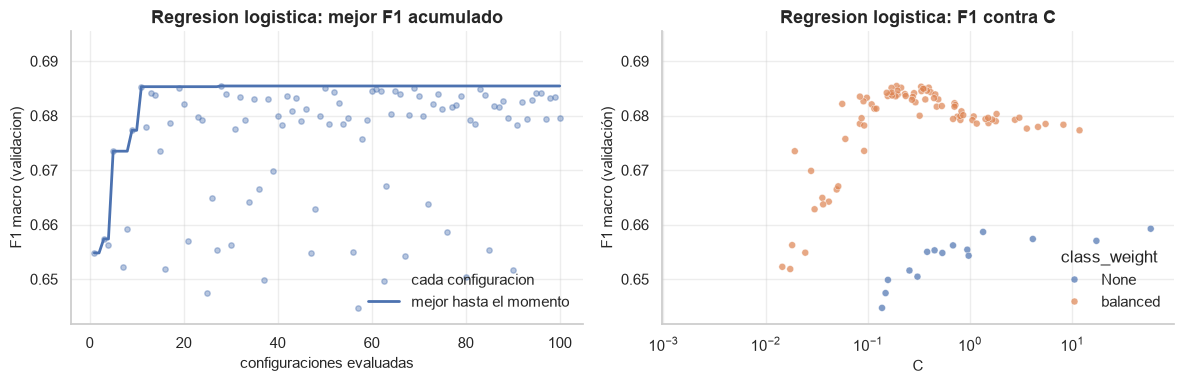

In [22]:
grafica_meseta("Regresion logistica", param="C", separar_por="class_weight")

**Qué hace el código.**

- Grafica la meseta de la búsqueda y el F1 contra `C`, separando por `class_weight`.
- Las figuras se guardan en `Images/` con nombres que empiezan con `5_meseta_`.

**Lectura.**

- **Meseta:** el mejor F1 macro llega a ≈ 0.685 alrededor de la configuración 11 y en las 90 configuraciones restantes no mejora de forma apreciable. La búsqueda llegó a una meseta; más configuraciones no cambiarían el resultado.
- **`class_weight` es el factor más importante:** el panel derecho muestra dos bandas separadas. Con `"balanced"` (naranja), el F1 macro llega a ≈ 0.685; sin ponderar (azul), no pasa de ≈ 0.66. Al dar más peso a *enrolled*, el modelo la predice más, y como el F1 macro pesa igual a las tres clases, el promedio sube.
- **`C`:** el F1 es máximo con regularización moderada, C entre 0.1 y 0.4. Con C < 0.05 la regularización es demasiado fuerte y el F1 cae rápido (subajuste); con C > 1 baja poco a poco (el modelo empieza a ajustar ruido).
- **`l1_ratio`** casi no influye: las mejores configuraciones tienen valores entre 0.1 y 0.6. L1 y L2 dan resultados muy parecidos en este problema.

**Resultado:** F1 macro = **0.6854 ± 0.0185** con C ≈ 0.19, `l1_ratio` ≈ 0.51 (elastic-net) y `class_weight="balanced"`, contra 0.6576 con los valores por defecto (+0.028). La búsqueda tardó unos 105 s.

---

### 5.2 SVM

#### Cómo funciona

- **Margen máximo.** Para dos clases, el SVM busca la frontera que las separa dejando el mayor **margen** posible, es decir, la mayor distancia a los estudiantes más cercanos de cada lado. Solo esos estudiantes cercanos a la frontera, los **vectores de soporte**, la definen; los que están lejos no influyen.
- **Margen suave.** Las clases se traslapan, así que se permite que algunos estudiantes queden dentro del margen o del lado equivocado, con un castigo por cada uno. `C` controla ese castigo: C pequeño acepta más errores a cambio de un margen amplio y una frontera simple; C grande intenta clasificar bien a casi todos.
- **Kernel.** Con kernel lineal, la frontera es un hiperplano, igual que en la regresión logística. Con kernel **RBF**, la decisión es una suma ponderada de **similitudes** con los vectores de soporte, $f(\mathbf{x}) = \sum_i \alpha_i\, y_i\, K(\mathbf{x}_i, \mathbf{x}) + b$, donde $K(\mathbf{x}, \mathbf{x}') = e^{-\gamma \lVert \mathbf{x} - \mathbf{x}' \rVert^2}$ vale 1 si los dos estudiantes son iguales y tiende a 0 cuando se alejan. Así la frontera puede curvarse. `gamma` fija qué tan rápido cae la similitud: gamma grande hace que cada vector de soporte solo influya en su vecindad.
- **Tres clases.** `SVC` entrena un SVM por cada par de clases (*dropout* vs. *enrolled*, *dropout* vs. *graduate*, *enrolled* vs. *graduate*), y cada estudiante se asigna a la clase que gana más de esas tres votaciones.
- **`class_weight="balanced"`** multiplica `C` por el peso de la clase: un *enrolled* mal clasificado cuesta ≈ 1.86 veces más, y la frontera se aleja de esa clase para predecirla más.
- No da probabilidades directamente: solo de qué lado de la frontera cae cada estudiante.

#### Por qué se trata así la información

- **Numéricos y ordinal → `StandardScaler`.** El kernel RBF depende de la distancia $\lVert \mathbf{x} - \mathbf{x}' \rVert^2$. Sin escalar, la nota de admisión y la nota previa decidirían ≈ 74 % de esa distancia (sección 2.9) y las materias aprobadas casi no contarían. Además, `gamma` solo tiene una interpretación razonable si todas las columnas están en escalas comparables. En el kernel lineal pasa lo mismo que en la logística: `C` castiga los coeficientes, que dependen de las unidades.
- **Nominales → one-hot.** Con los códigos tal cual, la carrera 9991 quedaría "lejísimos" de la 33 y "cerca" de la 9853 sin ninguna razón. Con one-hot, dos carreras distintas quedan siempre a la misma distancia, sin importar su código.
- **Binarios sin cambios**, y categorías raras agrupadas (`min_frequency=30`) para no agregar decenas de columnas casi vacías a la distancia.

**Espacio de búsqueda (60 configuraciones):**

| Hiperparámetro | Rango | Escala | Qué controla |
|---|---|---|---|
| `kernel` | `"linear"`, `"rbf"` | — | Forma de la frontera: un hiperplano (lineal) o una frontera curva construida a partir de distancias (RBF) |
| `C` | 10⁻² – 10² | logarítmica | Penalización por cada punto mal clasificado o dentro del margen: C pequeño = margen amplio y modelo más simple; C grande = el modelo intenta clasificar bien cada punto |
| `gamma` | 10⁻⁴ – 10⁰ | logarítmica | **Solo con RBF.** Alcance de cada vector de soporte: gamma pequeño = influencia amplia y frontera suave; gamma grande = influencia local y frontera muy irregular (sobreajuste) |
| `class_weight` | `None`, `"balanced"` | — | Igual que en la regresión logística: da más peso a *enrolled* |

Detalles fijos:

- **Espacio condicional:** `gamma` solo se propone cuando `kernel="rbf"`. Con el kernel lineal no existe, y Optuna no gasta configuraciones en él.
- **No se incluye el kernel polinomial:** con 3539 estudiantes y ~70 columnas después del one-hot es mucho más lento, y el RBF ya cubre las fronteras no lineales.
- **60 configuraciones en lugar de 100:** cada configuración del SVM tarda bastante más que en la regresión logística, sobre todo con C grande. Con 60 se respeta el mínimo de 50 y la gráfica de meseta muestra si alcanzan.
- `cache_size=1000` (MB): el SVM guarda en memoria los productos del kernel que ya calculó; con más caché recalcula menos y entrena más rápido, sin cambiar el resultado.

In [23]:
def crear_svm(trial):
    kernel = trial.suggest_categorical("kernel", ["linear", "rbf"])
    params = {
        "C": trial.suggest_float("C", 1e-2, 1e2, log=True),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
    }
    if kernel == "rbf":
        params["gamma"] = trial.suggest_float("gamma", 1e-4, 1e0, log=True)

    modelo = SVC(kernel=kernel, cache_size=1000, random_state=SEED, **params)
    return Pipeline([("prep", prep_escalado()), ("modelo", modelo)])


optimizar("SVM", crear_svm, n_trials=60)

SVM: 60 configuraciones en 91 s
Mejor F1 macro: 0.6820 +- 0.0216
Mejores hiperparametros: {'kernel': 'rbf', 'C': 1.614029086528123, 'class_weight': 'balanced', 'gamma': 0.02556814549636102}


**Qué hace el código.**

- `crear_svm(trial)` elige el kernel, `C` y `class_weight`; solo si el kernel es RBF propone también `gamma`.
- Arma el pipeline con `prep_escalado()` y `SVC`, y `optimizar` evalúa 60 configuraciones.

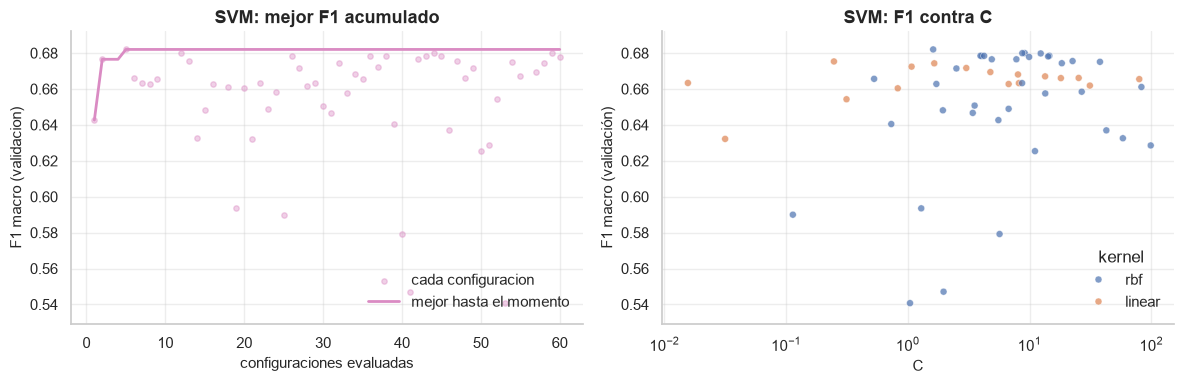

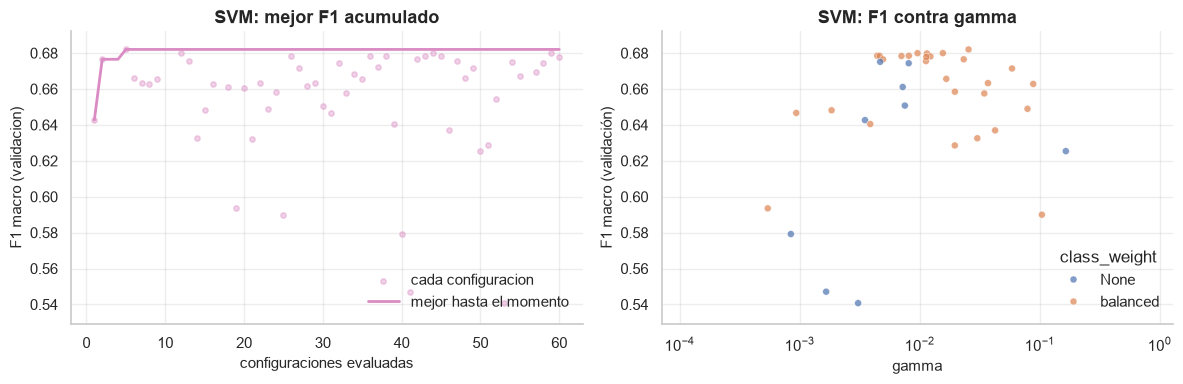

In [24]:
grafica_meseta("SVM", param="C", separar_por="kernel")
grafica_meseta("SVM", param="gamma", separar_por="class_weight")

**Qué hace el código.**

- Primera gráfica: F1 contra `C`, separando por kernel.
- Segunda gráfica: F1 contra `gamma`, separando por `class_weight`. Las configuraciones lineales no tienen `gamma` y no aparecen en el panel derecho.
- Las figuras se guardan en `Images/` con nombres que empiezan con `5_meseta_`.

**Lectura.**

- **Meseta:** el mejor F1 macro (≈ 0.682) aparece ya en la configuración 5, y en las 55 restantes ninguna lo supera; varias quedan muy cerca (≈ 0.680). La búsqueda llegó a una meseta muy pronto.
- **`kernel`:** el RBF apenas supera al lineal. La mejor configuración lineal queda en ≈ 0.676 y la mejor RBF en ≈ 0.682, una diferencia de 0.006, menor que la desviación entre pliegues (≈ 0.02). El lineal es además más estable: todas sus configuraciones con C > 0.1 quedan entre 0.655 y 0.676, mientras que el RBF va de 0.54 a 0.68 según `gamma`. Igual que en la regresión logística, la frontera entre clases es casi lineal y el kernel no lineal aporta poco.
- **`gamma` es el hiperparámetro más influyente del RBF:** las mejores configuraciones están entre 0.005 y 0.03. Con gamma < 0.002 cada vector de soporte influye sobre casi todo el espacio, la frontera queda demasiado suave y el F1 cae a 0.54–0.65 (subajuste). Con gamma > 0.05 la frontera se vuelve muy local y el F1 baja de nuevo (sobreajuste).
- **`class_weight`:** como en la regresión logística, `"balanced"` domina las mejores configuraciones. Las que no ponderan las clases quedan casi todas por debajo de 0.665.
- **`C`:** con el RBF, el mejor F1 aparece con C entre 1 y 20. Con C > 30 el F1 tiende a bajar, porque el modelo intenta clasificar bien cada punto de entrenamiento.

**Resultado:** F1 macro = **0.6820 ± 0.0216** con kernel RBF, C ≈ 1.61, gamma ≈ 0.026 y `class_weight="balanced"`, contra 0.6402 con los valores por defecto (+0.042). Es la mayor ganancia por optimizar hasta ahora, pero el resultado no supera a la regresión logística (0.6854) y la búsqueda tardó unos 91 s con 60 configuraciones, contra 105 s de la logística con 100 (≈ 1.5 s por configuración contra ≈ 1.0 s).

---

### 5.3 kNN

#### Cómo funciona

- **No construye un modelo.** "Entrenar" es solo guardar a los estudiantes de entrenamiento.
- **Predecir es buscar parecidos.** Para un estudiante nuevo, calcula su distancia a todos los estudiantes guardados, toma los $k$ más cercanos y predice la clase más votada entre ellos. Con `weights="distance"`, cada vecino vota con peso $1/d$, así que los más cercanos cuentan más.
- **La distancia.** Se usa la distancia de Minkowski: con `p=1` es la de Manhattan, $\sum_j |x_j - x'_j|$, y con `p=2` es la euclidiana, $\sqrt{\sum_j (x_j - x'_j)^2}$. La euclidiana eleva al cuadrado las diferencias, así que una sola columna con una diferencia grande pesa más que en Manhattan.
- **No tiene `class_weight`.** Cada vecino vota por su clase, y como *enrolled* es solo el 18 % de los datos, rara vez gana la votación, sobre todo con $k$ grande.
- Su supuesto es que **estudiantes cercanos en el espacio de atributos terminan igual**. Todo depende de qué significa "cercano".

#### Por qué se trata así la información

- **Es el modelo más sensible al preprocesamiento, porque solo usa distancias.**
- **Numéricos y ordinal → escalados.** Sin escalar, la distancia la decidirían casi solo la nota de admisión, la nota previa y la edad (sección 2.9), y dos estudiantes serían "vecinos" por tener notas de admisión parecidas aunque uno haya aprobado todo y el otro nada.
- **El escalador es un hiperparámetro.** Lo que decide cuánto pesa una columna en la distancia es su varianza (sección 2.9). Con `StandardScaler`, cada numérico tiene varianza 1, más que cualquier columna binaria o one-hot (≤ 0.25). Con `MinMaxScaler`, los numéricos quedan con varianzas de 0.003 a 0.1 y pesan menos que los binarios. Cuál reparto conviene se decide con validación cruzada.
- **Nominales → one-hot, con categorías raras agrupadas.** Por la misma razón que en el SVM, y además porque kNN empeora con muchas dimensiones: con decenas de columnas, todas las distancias se parecen y el "vecino más cercano" deja de ser informativo (maldición de la dimensionalidad). Agrupar las categorías raras le quita columnas casi vacías.

**Espacio de búsqueda (100 configuraciones):**

| Hiperparámetro | Rango | Escala | Qué controla |
|---|---|---|---|
| `n_neighbors` | 1 – 75 | lineal | Número de vecinos que votan: k pequeño = frontera muy irregular que sigue el ruido (sobreajuste); k grande = frontera suave, pero la clase mayoritaria (*graduate*) gana más votos |
| `weights` | `"uniform"`, `"distance"` | — | Si todos los vecinos votan igual o si los más cercanos pesan más (peso = 1/distancia) |
| `p` | 1, 2 | — | Distancia: 1 = Manhattan (suma de diferencias absolutas), 2 = euclidiana. Manhattan se ve menos afectada por una sola columna con diferencia grande |
| `escalador` | `StandardScaler`, `MinMaxScaler` | — | Cómo se escalan los numéricos y el ordinal (ver 4.2): estandarizados (≈ −3 a +3) o en [0, 1], en igualdad con los binarios y las columnas one-hot |

Detalles fijos:

- **kNN no tiene `class_weight`:** a diferencia de la regresión logística y el SVM, no hay forma directa de darle más peso a *enrolled*. Cada vecino vota por su clase, y como *enrolled* es solo el 18 % de los datos, rara vez gana la votación. Esto pone un límite al F1 macro que kNN puede alcanzar.
- **Escala lineal para `n_neighbors`:** es un conteo, y entre 1 y 75 no cambia por órdenes de magnitud.
- **Es rápido de evaluar:** kNN no entrena (solo guarda los datos), así que 100 configuraciones toman poco tiempo.

In [25]:
ESCALADORES = {"standard": StandardScaler, "minmax": MinMaxScaler}

def crear_knn(trial):
    escalador = trial.suggest_categorical("escalador", list(ESCALADORES))
    modelo = KNeighborsClassifier(
        n_neighbors=trial.suggest_int("n_neighbors", 1, 75),
        weights=trial.suggest_categorical("weights", ["uniform", "distance"]),
        p=trial.suggest_categorical("p", [1, 2]),
    )
    return Pipeline([("prep", prep_escalado(ESCALADORES[escalador]())), ("modelo", modelo)])


optimizar("kNN", crear_knn, n_trials=100)

kNN: 100 configuraciones en 16 s
Mejor F1 macro: 0.5733 +- 0.0153
Mejores hiperparametros: {'escalador': 'standard', 'n_neighbors': 7, 'weights': 'uniform', 'p': 1}


**Qué hace el código.**

- `ESCALADORES` relaciona el nombre de cada escalador con su clase.
- `crear_knn(trial)` elige el escalador, `n_neighbors`, `weights` y `p`, y arma el pipeline con `prep_escalado` usando el escalador elegido.
- `optimizar` evalúa 100 configuraciones.

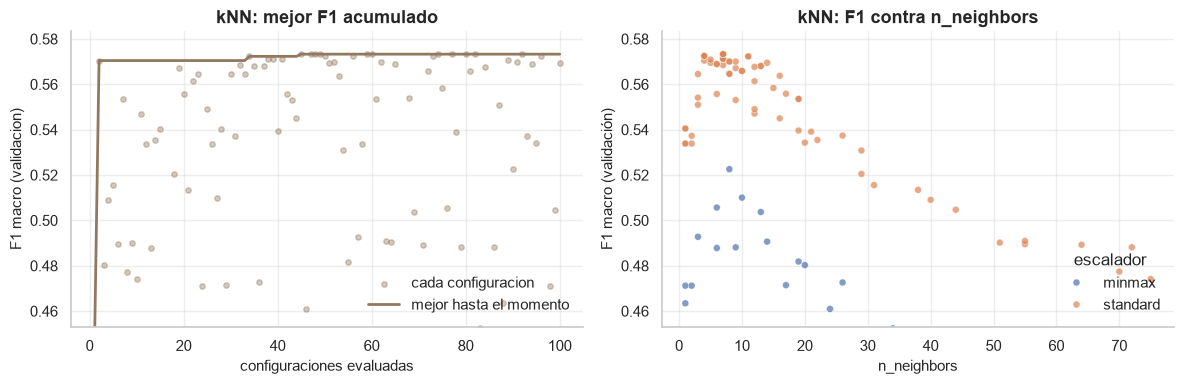

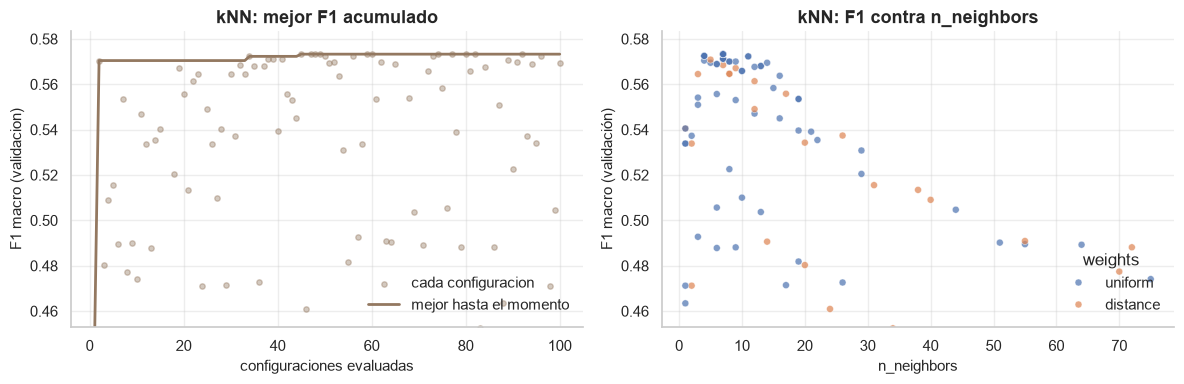

In [26]:
grafica_meseta("kNN", param="n_neighbors", log=False, separar_por="escalador")
grafica_meseta("kNN", param="n_neighbors", log=False, separar_por="weights")

**Qué hace el código.**

- Grafica el F1 contra `n_neighbors` en escala lineal, separando primero por escalador y después por `weights`.
- Las figuras se guardan en `Images/` con nombres que empiezan con `5_meseta_`.

**Lectura.**

- **Meseta:** la configuración 2 ya llega a ≈ 0.570 y el máximo (≈ 0.573) aparece cerca de la configuración 45; después no mejora. La ganancia de toda la búsqueda es de apenas 0.003 sobre esa segunda configuración.
- **El escalador es el factor más importante, y el resultado es el contrario al esperado en 4.2:** con `StandardScaler` (naranja) el F1 llega a ≈ 0.573; con `MinMaxScaler` (azul) no pasa de ≈ 0.52. Lo que importa no es el rango sino la **varianza**, que es lo que cada atributo aporta a la distancia (ver 2.9). Estandarizado, cada numérico tiene varianza 1, más que cualquier columna binaria o one-hot (varianza ≤ 0.25). En [0, 1], en cambio, ningún numérico pasa de ≈ 0.1 de varianza (las materias aprobadas quedan en ≈ 0.014), mientras que binarios como `Gender` o `Displaced` tienen ≈ 0.23–0.25. Así, la distancia la deciden sobre todo los ~50 binarios y columnas one-hot (atributos demográficos y la carrera), y los atributos académicos del 1er semestre, que son los más informativos (ver 2.6), pierden peso.
- **`n_neighbors`:** el F1 es máximo con k entre 4 y 13 y baja de forma sostenida a partir de k ≈ 15, hasta ≈ 0.47–0.49 con k > 50. Con muchos vecinos, la votación la gana casi siempre la clase mayoritaria (*graduate*) y *enrolled* casi nunca se predice. Es el efecto de no tener `class_weight` (ver detalles fijos).
- **`weights` y `p`:** casi no influyen. Con k pequeño, `"uniform"` y `"distance"` dan valores mezclados y muy parecidos; la mejor configuración usa `"uniform"` y Manhattan (`p=1`).

**Resultado:** F1 macro = **0.5733 ± 0.0153** con `StandardScaler`, k = 7, `weights="uniform"` y `p=1`, contra 0.5675 con los valores por defecto (+0.006). La búsqueda tardó unos 16 s. Es por mucho el peor de los clasificadores optimizados hasta ahora (≈ 0.11 por debajo de la regresión logística y el SVM). Hay dos razones: no puede compensar el desbalance de clases, y las ~70 dimensiones después del one-hot hacen que las distancias sean poco informativas (maldición de la dimensionalidad).

---

### 5.4 Árbol de decisión

#### Cómo funciona

- **Preguntas encadenadas.** El árbol divide a los estudiantes con preguntas sobre un solo atributo a la vez, del tipo "¿materias aprobadas ≤ 3?". Cada respuesta lleva a otra pregunta, hasta llegar a una **hoja**, que predice la clase más común de los estudiantes que llegaron ahí.
- **Cómo elige cada pregunta.** En cada nodo prueba todos los atributos y todos los cortes posibles, y se queda con el que deja a los dos grupos hijos más "puros", es decir, con mayoría clara de una clase. La impureza se mide con Gini, $1 - \sum_k p_k^2$, o con entropía, $-\sum_k p_k \log p_k$, donde $p_k$ es la proporción de la clase $k$ en el nodo. Ambas valen 0 si el nodo tiene una sola clase.
- **Cuándo para.** Sin límites, sigue dividiendo hasta que cada hoja es pura, y termina memorizando el entrenamiento. `max_depth` limita el número de preguntas encadenadas y `min_samples_leaf` el mínimo de estudiantes por hoja.
- **Poda (`ccp_alpha`).** Después de crecer el árbol, elimina las ramas cuya mejora en impureza no compensa las hojas que agregan: minimiza $R(T) + \alpha \cdot |\text{hojas}|$, donde $R(T)$ es la impureza total del árbol.
- **`class_weight="balanced"`** cuenta a cada *enrolled* como ≈ 1.86 estudiantes al calcular la impureza y la clase de cada hoja.

#### Por qué se trata así la información

- **Sin escalado.** Cada pregunta compara un solo atributo con un umbral, así que solo importa el **orden** de los valores, no su escala. Estandarizar o llevar a [0, 1] no cambia qué estudiantes quedan de cada lado de ningún corte: el árbol resultante sería el mismo. Tampoco hay distancias ni penalizaciones que dependan de las unidades.
- **Nominales como enteros, sin one-hot.** Un corte como "¿Course ≤ 9200?" agrupa carreras según un orden arbitrario, pero el árbol puede encadenar cortes para aislar una carrera si eso ayuda. Con one-hot, en cambio, cada pregunta solo podría separar una carrera del resto, cada rama tendría pocos estudiantes y haría falta mucha más profundidad. En la práctica, el árbol final ni siquiera usó atributos nominales (sección 5.4).
- **Binarios sin cambios:** el corte en 0.5 los separa de forma natural.

**Espacio de búsqueda (100 configuraciones):**

| Hiperparámetro | Rango | Escala | Qué controla |
|---|---|---|---|
| `max_depth` | 2 – 20 | lineal | Número máximo de preguntas encadenadas: un árbol poco profundo es simple pero puede subajustar; uno profundo memoriza el entrenamiento |
| `min_samples_leaf` | 1 – 100 | lineal | Estudiantes mínimos en cada hoja: con valores grandes, ninguna regla se basa en unos pocos casos |
| `ccp_alpha` | 10⁻⁵ – 5·10⁻² | logarítmica | Poda por complejidad de costo: después de crecer el árbol, elimina las ramas que reducen poco la impureza en relación con las hojas que agregan. Valores grandes dejan un árbol de pocas hojas |
| `criterion` | `"gini"`, `"entropy"` | — | Medida de impureza para elegir cada corte |
| `class_weight` | `None`, `"balanced"` | — | Igual que en la regresión logística y el SVM: da más peso a *enrolled* al calcular la impureza |

Detalles fijos:

- **Sin preprocesamiento** (ver 4.2): el árbol recibe los códigos enteros tal cual, porque escalar no cambia ningún corte.
- **Tres formas de controlar el tamaño:** `max_depth` y `min_samples_leaf` limitan el árbol mientras crece; `ccp_alpha` lo poda después. Se buscan las tres juntas porque se compensan: un árbol profundo con poda fuerte puede quedar igual de simple que uno poco profundo sin poda.
- **`ccp_alpha` en escala logarítmica:** su efecto aparece en el rango 10⁻⁴–10⁻². Por encima de ≈ 0.05 el árbol queda reducido a uno o dos cortes.

In [27]:
def crear_arbol(trial):
    modelo = DecisionTreeClassifier(
        max_depth=trial.suggest_int("max_depth", 2, 20),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 100),
        ccp_alpha=trial.suggest_float("ccp_alpha", 1e-5, 5e-2, log=True),
        criterion=trial.suggest_categorical("criterion", ["gini", "entropy"]),
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
        random_state=SEED,
    )
    return Pipeline([("modelo", modelo)])


optimizar("Arbol de decision", crear_arbol, n_trials=100)

Arbol de decision: 100 configuraciones en 5 s
Mejor F1 macro: 0.6408 +- 0.0307
Mejores hiperparametros: {'max_depth': 20, 'min_samples_leaf': 19, 'ccp_alpha': 0.0049299250581314345, 'criterion': 'gini', 'class_weight': None}


**Qué hace el código.**

- `crear_arbol(trial)` propone `max_depth`, `min_samples_leaf`, `ccp_alpha` (escala logarítmica), `criterion` y `class_weight`.
- El pipeline solo tiene el árbol, sin preprocesamiento.
- `optimizar` evalúa 100 configuraciones.

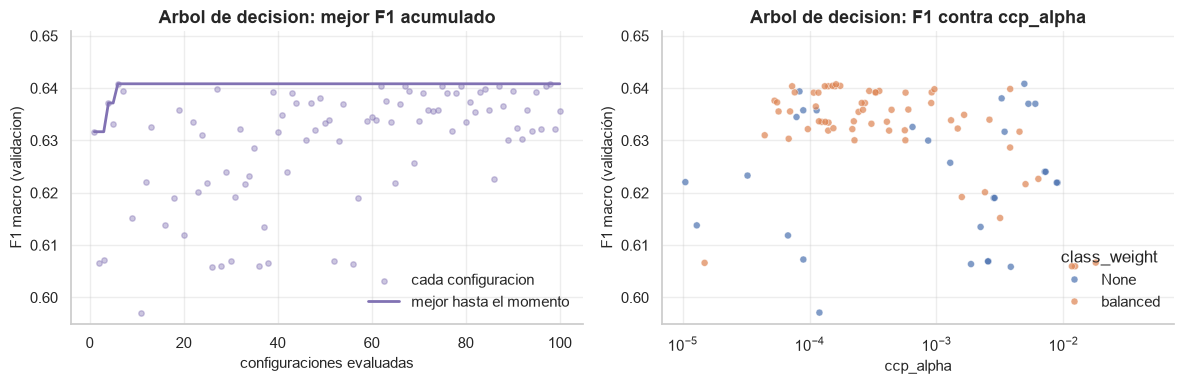

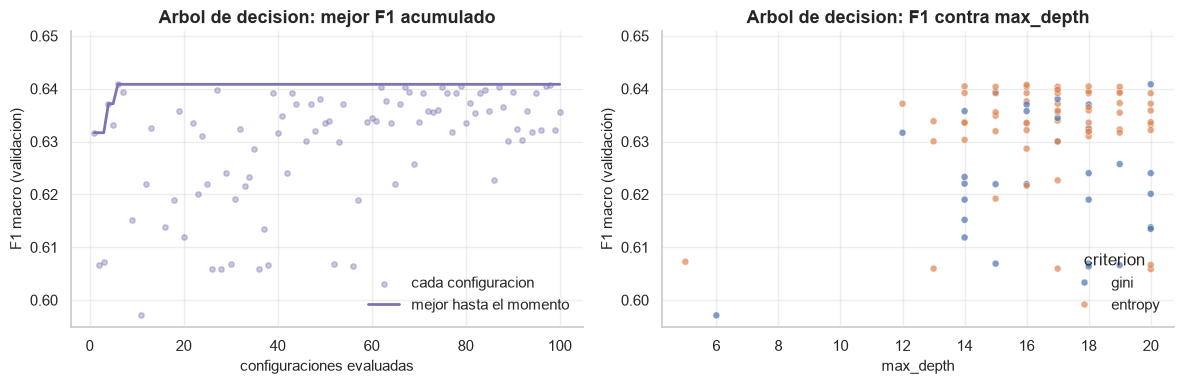

In [28]:
grafica_meseta("Arbol de decision", param="ccp_alpha", separar_por="class_weight")
grafica_meseta("Arbol de decision", param="max_depth", log=False, separar_por="criterion")

**Qué hace el código.**

- Primera gráfica: F1 contra `ccp_alpha`, separando por `class_weight`.
- Segunda gráfica: F1 contra `max_depth`, separando por `criterion`.
- Las figuras se guardan en `Images/` con nombres que empiezan con `5_meseta_`.

In [29]:
arbol = resultados["Arbol de decision"]["crear_pipeline"](
    optuna.trial.FixedTrial(resultados["Arbol de decision"]["study"].best_params)
).fit(X, y)["modelo"]

print("Profundidad real:", arbol.get_depth(), "  hojas:", arbol.get_n_leaves())
importancias = pd.Series(arbol.feature_importances_, index=X.columns)
importancias[importancias > 0].sort_values(ascending=False)

Profundidad real: 4   hojas: 8


Curricular units 1st sem (approved)   0.7372
Tuition fees up to date               0.1818
Curricular units 1st sem (enrolled)   0.0809
dtype: float64

**Qué hace el código.**

- Reconstruye el árbol con los mejores hiperparámetros (`FixedTrial` vuelve a llamar a `crear_arbol` con valores fijos) y lo entrena con todo `X`.
- Imprime su profundidad real y su número de hojas, y lista los atributos con importancia mayor que cero.

**Lectura.**

- **Meseta:** el mejor F1 macro (≈ 0.641) aparece en la configuración 6 y en las 94 restantes no mejora; varias configuraciones posteriores quedan en ≈ 0.640.
- **`ccp_alpha` es el factor más importante:** las mejores configuraciones tienen poda entre 5·10⁻⁵ y 5·10⁻³. Sin poda (< 2·10⁻⁵) el árbol sobreajusta y el F1 cae a ≈ 0.61–0.62; con poda > 10⁻² el árbol queda con muy pocos cortes y también baja.
- **`max_depth` no limita el árbol:** la búsqueda se concentró en profundidades de 14 a 20 y el mejor valor fue 20, pero con la poda el árbol final tiene solo **profundidad 4 y 8 hojas**. Lo que controla el tamaño es `ccp_alpha` (junto con `min_samples_leaf` = 19), no `max_depth`. Casi no se exploraron profundidades menores a 12, pero no hacía falta: la poda llega sola a un árbol pequeño.
- **El árbol usa solo 3 atributos:** materias aprobadas en el 1er semestre (importancia ≈ 0.74), colegiatura al día (≈ 0.18) y materias inscritas (≈ 0.08). Coincide con lo visto en 2.5 y 2.6: lo académico y lo económico del 1er semestre son las señales más fuertes.
- **`class_weight` y `criterion` casi no influyen:** la mejor configuración no pondera las clases, pero hay muchas configuraciones con `"balanced"` en ≈ 0.640. La diferencia (≈ 0.001) es mucho menor que la desviación entre pliegues. Gini y entropía dan resultados mezclados.

**Resultado:** F1 macro = **0.6408 ± 0.0307** con `ccp_alpha` ≈ 0.0049, `min_samples_leaf` = 19, `criterion="gini"` y sin `class_weight`, contra 0.5890 sin optimizar (+0.052, la mayor ganancia hasta ahora: el árbol por defecto crece sin límite y sobreajusta). La búsqueda tardó unos 5 s. Es el más inestable entre pliegues (desviación ≈ 0.031): con solo 8 hojas, mover unos cuantos estudiantes de un pliegue a otro puede cambiar un corte. A cambio, es el único modelo que se puede leer como un conjunto de reglas.

---

### 5.5 Naive Bayes

#### Cómo funciona

- **Teorema de Bayes.** La probabilidad de cada clase dados los atributos es proporcional a qué tan común es la clase por cómo de probables son esos atributos dentro de ella: $P(k \mid \mathbf{x}) \propto P(k)\, P(\mathbf{x} \mid k)$. Se predice la clase con mayor valor.
- **La suposición "ingenua".** Estimar $P(\mathbf{x} \mid k)$ con 30 atributos a la vez es imposible con 3539 estudiantes, así que se supone que los atributos son **independientes dentro de cada clase**: $P(\mathbf{x} \mid k) = \prod_j P(x_j \mid k)$. Basta con estimar la distribución de cada atributo por separado.
- **Entrenar es contar.** $P(k)$ es la proporción de cada clase (o 1/3 si los priors son uniformes). Lo que cambia entre variantes es cómo se estima $P(x_j \mid k)$:
  - **`CategoricalNB`:** con una tabla de frecuencias, $P(x_j = v \mid k) = \dfrac{n_{jvk} + \alpha}{n_k + \alpha\, m_j}$, donde $n_{jvk}$ es cuántos estudiantes de la clase $k$ tienen el valor $v$ y $m_j$ el número de valores posibles. El **suavizado** $\alpha$ evita que un valor que no apareció en una clase tenga probabilidad 0, lo que anularía todo el producto.
  - **`GaussianNB`:** supone que cada atributo sigue una campana (normal) dentro de cada clase, con la media y la varianza de esa clase. `var_smoothing` suma una pequeña cantidad a todas las varianzas para que ninguna campana sea demasiado angosta.
- La suposición de independencia casi nunca se cumple (aquí, materias inscritas, evaluadas y aprobadas están muy correlacionadas), y por eso las probabilidades salen demasiado extremas. Aun así, la clase con mayor probabilidad suele ser razonable.

#### Por qué se trata así la información

- **`CategoricalNB` necesita valores discretos**, porque estima cada probabilidad contando.
  - **Nominales → enteros 0, 1, 2… (`OrdinalEncoder`).** Aquí el número es solo la fila de la tabla de conteos: cada valor se cuenta por separado y su orden no importa. Por eso no hace falta one-hot, a diferencia de los modelos lineales y de distancias.
  - **Numéricos y ordinal → intervalos por cuantiles (`KBinsDiscretizer`).** Los cuantiles hacen que cada intervalo tenga aproximadamente el mismo número de estudiantes, así que ninguno queda casi vacío con probabilidades mal estimadas. `n_bins` equilibra perder detalle (pocos intervalos) contra tener pocos estudiantes por intervalo y clase (muchos intervalos).
  - **`CATEGORICAS` y `min_categories`** fijan el tamaño de cada tabla aunque un código no aparezca en un pliegue; con conteo 0, el suavizado $\alpha$ le da una probabilidad pequeña (sección 4.4).
- **`GaussianNB` usa one-hot en los nominales**, porque una campana sobre los códigos de carrera no tiene sentido. Aun así, los binarios y las columnas one-hot (solo 0 y 1) tampoco son campanas, y por eso esta variante falla (sección 4.5).
- **En ninguna variante se escala.** `CategoricalNB` cuenta y `GaussianNB` estima la media y la varianza de cada atributo por separado: cambiar las unidades no cambia ninguna decisión.

**Espacio de búsqueda (100 configuraciones):** la variante es un hiperparámetro más y cada una tiene su propio preprocesamiento (ver 4.3).

| Hiperparámetro | Variante | Rango | Escala | Qué controla |
|---|---|---|---|---|
| `variante` | — | `"categorico"`, `"gaussiano"` | — | `CategoricalNB` (cuenta frecuencias) o `GaussianNB` (supone una campana por atributo y clase) |
| `alpha` | categórico | 10⁻³ – 10¹ | logarítmica | Suavizado de Laplace: suma `alpha` a cada conteo, para que una combinación valor–clase que no aparece en el entrenamiento no tenga probabilidad 0 y anule todo el producto |
| `n_bins` | categórico | 2 – 20 | lineal | Intervalos en que se discretizan los numéricos y el ordinal: pocos pierden información; muchos dejan intervalos con pocos estudiantes y probabilidades mal estimadas |
| `var_smoothing` | gaussiano | 10⁻¹² – 10⁻¹ | logarítmica | Fracción de la varianza máxima que se suma a todas las varianzas, para que ninguna campana sea demasiado angosta |
| `priors` | ambas | estimadas, uniformes | — | Probabilidad previa de cada clase: estimadas de los datos (50 / 32 / 18 %) o iguales (1/3 cada una) |

Detalles fijos:

- **`priors` uniformes es el equivalente de `class_weight="balanced"`:** Naive Bayes no tiene `class_weight`, pero multiplica por P(clase). Con priors iguales, *enrolled* deja de estar penalizada por ser la clase más pequeña. En `CategoricalNB` se logra con `fit_prior=False`; en `GaussianNB`, con `priors=[1/3, 1/3, 1/3]`.
- **Espacio condicional:** `alpha` y `n_bins` solo se proponen con la variante categórica y `var_smoothing` solo con la gaussiana. Si TPE ve pronto que la gaussiana es mucho peor (como en la sección 4), dedicará casi todas las configuraciones a la categórica.
- `min_categories` se calcula con el mismo `n_bins` del discretizador, para que una categoría que aparezca solo en un pliegue de validación no rompa el modelo (ver 4.4).

In [30]:
def crear_naive_bayes(trial):
    variante = trial.suggest_categorical("variante", ["categorico", "gaussiano"])
    uniformes = trial.suggest_categorical("priors_uniformes", [False, True])

    if variante == "categorico":
        n_bins = trial.suggest_int("n_bins", 2, 20)
        modelo = CategoricalNB(
            alpha=trial.suggest_float("alpha", 1e-3, 1e1, log=True),
            fit_prior=not uniformes,
            min_categories=min_categorias(n_bins),
        )
        return Pipeline([("prep", prep_categorico(n_bins)), ("modelo", modelo)])

    modelo = GaussianNB(
        var_smoothing=trial.suggest_float("var_smoothing", 1e-12, 1e-1, log=True),
        priors=[1 / 3] * 3 if uniformes else None,
    )
    return Pipeline([("prep", prep_gaussiano), ("modelo", modelo)])


optimizar("Naive Bayes", crear_naive_bayes, n_trials=100)

Naive Bayes: 100 configuraciones en 7 s
Mejor F1 macro: 0.6320 +- 0.0114
Mejores hiperparametros: {'variante': 'categorico', 'priors_uniformes': False, 'n_bins': 12, 'alpha': 0.4448636561609948}


**Qué hace el código.**

- `crear_naive_bayes(trial)` elige la variante y si los priors son uniformes.
- Variante categórica: propone `n_bins` y `alpha`, y arma `prep_categorico(n_bins)` con `CategoricalNB` (`fit_prior=False` si los priors son uniformes).
- Variante gaussiana: propone `var_smoothing`, y arma `prep_gaussiano` con `GaussianNB` (priors de 1/3 si son uniformes).
- `optimizar` evalúa 100 configuraciones.

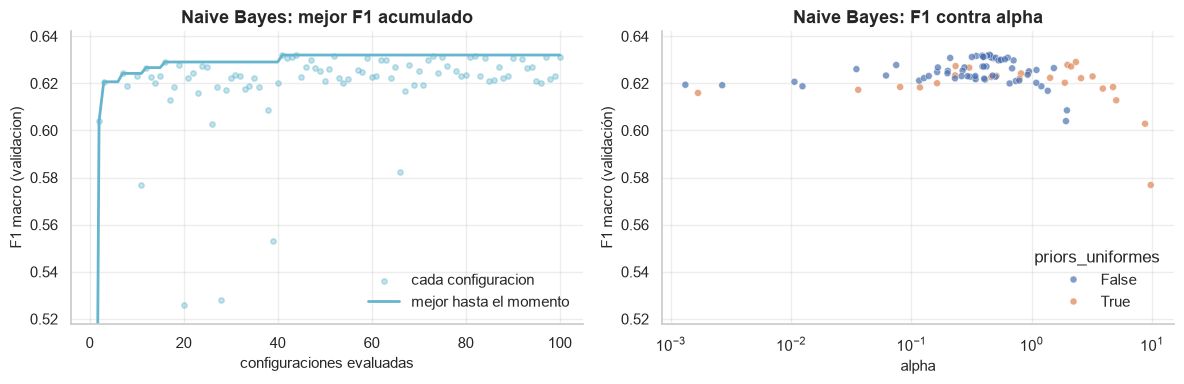

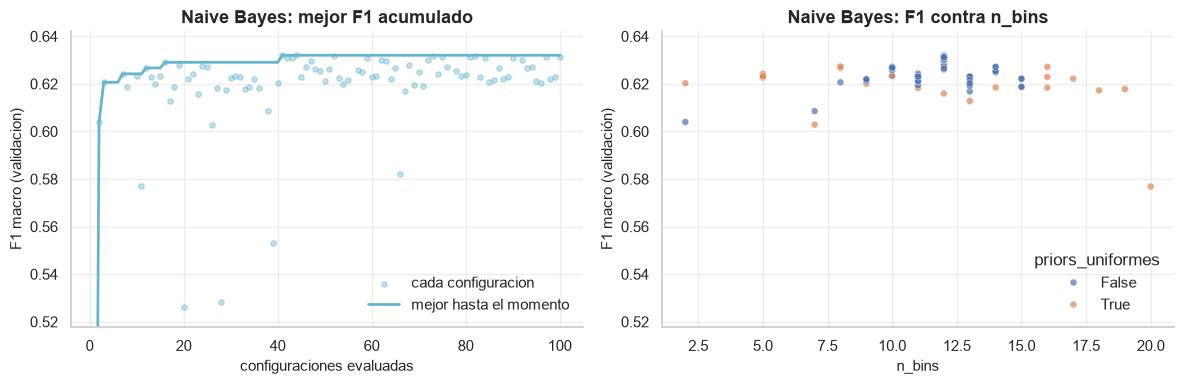

In [31]:
grafica_meseta("Naive Bayes", param="alpha", separar_por="priors_uniformes")
grafica_meseta("Naive Bayes", param="n_bins", log=False, separar_por="priors_uniformes")

**Qué hace el código.**

- Grafica el F1 contra `alpha` y contra `n_bins`, separando por `priors_uniformes`. Solo aparecen las configuraciones categóricas, que son las que tienen esos hiperparámetros.
- Las figuras se guardan en `Images/` con nombres que empiezan con `5_meseta_`.

**Lectura.**

- **Variante:** gana `CategoricalNB`. Las configuraciones gaussianas quedan por debajo de ≈ 0.53, como ya se vio en la sección 4, y TPE dejó de proponerlas pronto: casi toda la búsqueda se dedicó a la variante categórica.
- **Meseta:** el F1 sube rápido hasta ≈ 0.629 en la configuración 16 y alcanza el máximo (≈ 0.632) en la 41; en las 60 restantes no mejora. La mayoría de las configuraciones categóricas quedan en una franja angosta (0.615–0.632): Naive Bayes es poco sensible a sus hiperparámetros.
- **`alpha`:** el mejor rango está entre 0.2 y 0.8. Con alpha < 0.05 el F1 baja poco (≈ 0.62); con alpha > 2 el suavizado aplana las probabilidades y el F1 cae hasta ≈ 0.58 con alpha ≈ 10.
- **`n_bins`:** el máximo está en 12 intervalos. Con 2 intervalos se pierde información (≈ 0.60); con más de 15, cada intervalo tiene pocos estudiantes por clase, las probabilidades quedan mal estimadas y el F1 baja (≈ 0.58 con 20).
- **Los priors uniformes no ayudan, al contrario de `class_weight` en la regresión logística y el SVM:** las mejores configuraciones usan los priors estimados. Naive Bayes multiplica 30 probabilidades como si fueran independientes, y como muchos atributos están correlacionados (por ejemplo, materias inscritas, evaluadas y aprobadas), las probabilidades finales quedan muy cerca de 0 o de 1. Frente a eso, cambiar el prior de *enrolled* de 0.18 a 0.33 casi no mueve la decisión.

**Resultado:** F1 macro = **0.6320 ± 0.0114** con `CategoricalNB`, 12 intervalos, alpha ≈ 0.44 y priors estimados, contra 0.6155 sin optimizar (+0.017). La búsqueda tardó unos 7 s. Su desviación entre pliegues es la más baja de los cinco: es un modelo simple y estable.

---

## 6. Comparación y elección del clasificador final

### 6.1 Mejor configuración de cada clasificador

La tabla resume la mejor configuración de cada clasificador: su F1 macro en los 5 pliegues, el F1 con los valores por defecto (sección 4), la ganancia por optimizar y el tiempo de la búsqueda. En el caso de Naive Bayes, la línea base es `CategoricalNB`, la variante que ganó.

Como **los cinco se evaluaron con los mismos pliegues**, las comparaciones son **pareadas**: en la gráfica, cada línea gris une el F1 de los cinco modelos en un mismo pliegue. Si las líneas casi no se cruzan, la diferencia entre dos modelos es consistente en todos los pliegues y no un efecto de cómo se partieron los datos.

In [32]:
BASE = {
    "Regresion logistica": "Regresion logistica",
    "Arbol de decision": "Arbol de decision",
    "Naive Bayes": "Naive Bayes (categorico)",
    "kNN": "kNN",
    "SVM": "SVM",
}
f1_base = tabla_base.set_index("modelo")["F1 macro (media)"]

filas = []
for nombre in MODELOS:
    study = resultados[nombre]["study"]
    f1 = np.array(study.best_trial.user_attrs["f1_pliegues"])
    base = f1_base[BASE[nombre]]
    filas.append([nombre, f1.mean(), f1.std(), base, f1.mean() - base,
                  len(study.trials), resultados[nombre]["tiempo"]])

tabla_comp = pd.DataFrame(filas, columns=[
    "modelo", "F1 macro (media)", "F1 macro (desv.)", "F1 por defecto",
    "ganancia", "configuraciones", "tiempo (s)",
]).sort_values("F1 macro (media)", ascending=False).reset_index(drop=True)
tabla_comp

,modelo,F1 macro (media),F1 macro (desv.),F1 por defecto,ganancia,configuraciones,tiempo (s)
0,Regresion logistica,0.6854,0.0185,0.6576,0.0279,100,104.6419
1,SVM,0.6820,0.0216,0.6402,0.0418,60,90.7225
2,Arbol de decision,0.6408,0.0307,0.5890,0.0518,100,4.9897
3,Naive Bayes,0.6320,0.0114,0.6155,0.0166,100,6.5380
4,kNN,0.5733,0.0153,0.5675,0.0058,100,16.4664


**Qué hace el código.**

- `BASE` relaciona cada modelo optimizado con su versión por defecto de la sección 4.5 (para Naive Bayes, la categórica).
- Para cada modelo toma los 5 F1 de su mejor configuración y reúne en `tabla_comp` la media, la desviación, el F1 por defecto, la ganancia, el número de configuraciones y el tiempo de la búsqueda.
- Ordena la tabla de mejor a peor F1 macro.

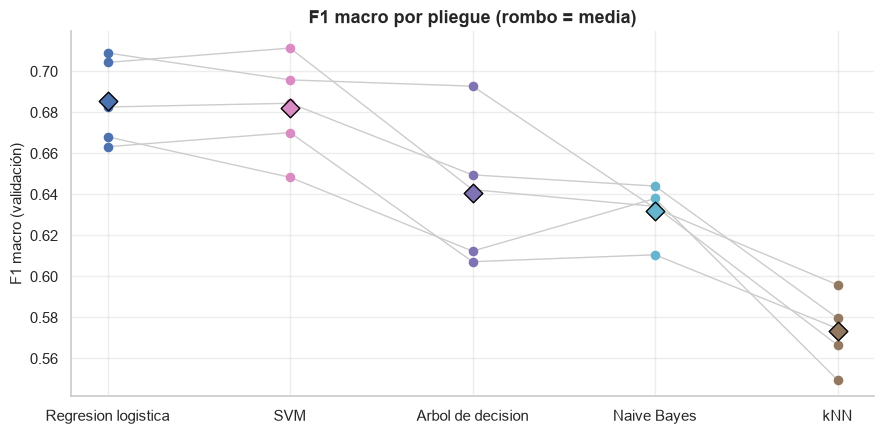

Regresión logística − SVM por pliegue: [-0.0069, 0.0197, -0.007, -0.0018, 0.0131]
La logística gana en 2 de 5 pliegues; diferencia media +0.0034


In [33]:
orden = tabla_comp["modelo"].tolist()
f1_pliegues = pd.DataFrame(
    {n: resultados[n]["study"].best_trial.user_attrs["f1_pliegues"] for n in orden},
    index=[f"pliegue {i + 1}" for i in range(len(PLIEGUES))],
)

fig, ax = plt.subplots(figsize=(9, 4.5))
for _, fila in f1_pliegues.iterrows():
    xs = np.arange(len(orden))
    ys = fila.to_numpy(dtype=float)
    ax.plot(xs, ys, color="0.8", lw=1, zorder=1)
for n in orden:
    ax.scatter([n] * len(f1_pliegues), f1_pliegues[n], color=COLORES_MODELO[n], s=35, zorder=2)
    ax.scatter(n, f1_pliegues[n].mean(), color=COLORES_MODELO[n], marker="D", s=90,
               edgecolor="black", zorder=3)
ax.set_ylabel("F1 macro (validación)")
ax.set_title("F1 macro por pliegue (rombo = media)")
plt.tight_layout()
mostrar("6_1_f1_por_pliegue")

dif = f1_pliegues["Regresion logistica"] - f1_pliegues["SVM"]
print("Regresión logística − SVM por pliegue:", dif.round(4).tolist())
print(f"La logística gana en {(dif > 0).sum()} de {len(dif)} pliegues; diferencia media {dif.mean():+.4f}")

**Qué hace el código.**

- Arma una tabla con los 5 F1 por pliegue de cada modelo, en el orden de `tabla_comp`.
- Dibuja un punto por pliegue, una línea gris que une el mismo pliegue entre modelos y un rombo con la media de cada modelo.
- Calcula la diferencia entre la regresión logística y el SVM en cada pliegue y en cuántos pliegues gana la logística.
- Guarda la figura en `Images/6_1_f1_por_pliegue.png`.

**Lectura.**

- **Dos grupos claros:** la regresión logística y el SVM (≈ 0.68) quedan por encima del árbol y Naive Bayes (≈ 0.63–0.64), y kNN queda último (≈ 0.57). En la gráfica pareada, las líneas casi no se cruzan entre grupos: en todos los pliegues, la logística y el SVM superan a Naive Bayes y a kNN. Esa diferencia es consistente y no depende de cómo se partieron los datos.
- **Logística contra SVM, un empate:** la logística gana en solo **2 de 5 pliegues**. Las diferencias van de −0.007 a +0.020 y la media es +0.003. Las líneas entre las dos columnas se cruzan: no hay un ganador consistente. En desempeño, los dos modelos son equivalentes.
- **El árbol es el más irregular:** en un pliegue llega a ≈ 0.69, a la altura de los mejores, y en otros dos cae a ≈ 0.61. Es lo esperado para un árbol de 8 hojas: unos cuantos estudiantes que cambian de pliegue mueven un corte.
- **Ganancia por optimizar:** el árbol (+0.052) y el SVM (+0.042) son los que más ganaron, porque sus valores por defecto eran los peores (el árbol sin poda sobreajusta; el SVM sin `class_weight` ignora a *enrolled*). kNN casi no ganó (+0.006): su límite no son los hiperparámetros, sino la falta de `class_weight` y la dimensión de los datos.

---

### 6.2 Elección del clasificador final

| Lugar | Modelo | F1 macro |
|---|---|---|
| 1 | Regresión logística | 0.6854 ± 0.0185 |
| 2 | SVM (RBF) | 0.6820 ± 0.0216 |
| 3 | Árbol de decisión | 0.6408 ± 0.0307 |
| 4 | Naive Bayes (categórico) | 0.6320 ± 0.0114 |
| 5 | kNN | 0.5733 ± 0.0153 |

Hay dos grupos claros. La **regresión logística y el SVM** quedan ≈ 0.04 por encima del resto: son los dos que usan one-hot con escalado y que pueden compensar el desbalance con `class_weight="balanced"`. Entre ellos la diferencia es de solo 0.003, muy por debajo de la desviación entre pliegues (≈ 0.02).

Con una diferencia tan pequeña, el F1 medio no basta para decidir. La celda siguiente compara a los dos candidatos, con los mismos pliegues, en todo lo que podría desempatar: F1 por pliegue y por clase, estabilidad, recall de *dropout*, cuántos desertores alcanzaría la escuela y tiempos.

In [34]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, recall_score

def pipe_optimo(nombre):
    """Pipeline de un modelo con los mejores hiperparametros que encontro Optuna"""
    return resultados[nombre]["crear_pipeline"](
        optuna.trial.FixedTrial(resultados[nombre]["study"].best_params)
    )

candidatos = ["Regresion logistica", "SVM"]
otro = {"Regresion logistica": "SVM", "SVM": "Regresion logistica"}
f1_cand = {n: np.array(resultados[n]["study"].best_trial.user_attrs["f1_pliegues"]) for n in candidatos}
pred_cand = {n: cross_val_predict(pipe_optimo(n), X, y, cv=PLIEGUES, n_jobs=-1) for n in candidatos}

filas = {}
for n in candidatos:
    p = pred_cand[n]
    fila = {
        "F1 macro (media)": f1_cand[n].mean(),
        "F1 macro (desv.)": f1_cand[n].std(),
        "pliegues ganados": (f1_cand[n] > f1_cand[otro[n]]).sum(),
    }
    for c, v in zip(CLASES, f1_score(y, p, labels=CLASES, average=None)):
        fila[f"F1 {c}"] = v
    fila["recall dropout"] = recall_score(y, p, labels=["dropout"], average=None)[0]
    fila["% desertores no predichos graduate"] = ((p != "graduate") & (y == "dropout")).sum() / (y == "dropout").sum() * 100
    fila["segundos por configuración"] = resultados[n]["tiempo"] / len(resultados[n]["study"].trials)
    inicio = time.perf_counter()
    pipe_optimo(n).fit(X, y)
    fila["ajuste final (s)"] = time.perf_counter() - inicio
    filas[n] = fila

dif = f1_cand["SVM"] - f1_cand["Regresion logistica"]
print("SVM − Regresión logística por pliegue:", dif.round(4).tolist())
print(f"Diferencia media {dif.mean():+.4f}; desviación de la diferencia entre pliegues {dif.std():.4f}")
print(f"Los dos modelos predicen la misma clase en el "
      f"{(pred_cand['SVM'] == pred_cand['Regresion logistica']).mean() * 100:.1f} % de los estudiantes")

pd.DataFrame(filas)

SVM − Regresión logística por pliegue: [0.0069, -0.0197, 0.007, 0.0018, -0.0131]
Diferencia media -0.0034; desviación de la diferencia entre pliegues 0.0110
Los dos modelos predicen la misma clase en el 89.0 % de los estudiantes


,Regresion logistica,SVM
F1 macro (media),0.6854,0.6820
F1 macro (desv.),0.0185,0.0216
pliegues ganados,2.0000,3.0000
F1 dropout,0.7511,0.7403
F1 enrolled,0.4894,0.4865
F1 graduate,0.8155,0.8190
recall dropout,0.6992,0.6719
% desertores no predichos graduate,89.7977,88.9182
segundos por configuración,1.0464,1.5120
ajuste final (s),0.6279,0.5246


**Qué hace el código.**

- `pipe_optimo(nombre)` reconstruye el pipeline de un modelo con los mejores hiperparámetros de su búsqueda (`FixedTrial` vuelve a llamar a su función `crear_...` con valores fijos).
- Para la regresión logística y el SVM toma los 5 F1 de su mejor configuración y obtiene con `cross_val_predict` la predicción de validación cruzada de cada estudiante, con los mismos `PLIEGUES`.
- Reúne en una tabla, para cada uno: F1 macro (media y desviación), pliegues que le gana al otro, F1 de cada clase, recall de *dropout*, % de desertores que no se predicen como *graduate*, segundos por configuración en la búsqueda y tiempo de ajuste del modelo final.
- Imprime la diferencia SVM − logística en cada pliegue, su media y su desviación, y el % de estudiantes en que los dos modelos predicen la misma clase.

**Lectura y decisión.**

| | Regresión logística | SVM (RBF) |
|---|---|---|
| F1 macro | 0.6854 ± 0.0185 | 0.6820 ± 0.0216 |
| Pliegues ganados (comparación pareada) | 2 de 5 | **3 de 5** |
| F1 *dropout* / *enrolled* / *graduate* | 0.751 / 0.489 / 0.816 | 0.740 / 0.487 / 0.819 |
| Precisión de *dropout* | 0.811 | **0.824** |
| Recall de *dropout* | **0.699** | 0.672 |
| Desertores no predichos como *graduate* | **89.8 %** | 88.9 % |
| Tiempo por configuración en la búsqueda | **≈ 1.0 s** | ≈ 1.5 s |
| Ajuste del modelo final | < 1 s | < 1 s |

- **Empatan en desempeño.** La diferencia media SVM − logística es −0.0034, y la diferencia entre los dos varía ±0.011 de un pliegue a otro: la ventaja de la logística es menos de un tercio de ese ruido. Además, no es consistente: el SVM gana en 3 de los 5 pliegues.
- **Tienen la misma estabilidad.** Las desviaciones (0.0185 y 0.0216) son prácticamente iguales, y las dos están muy por debajo de la del árbol (0.031).
- **Casi siempre predicen lo mismo.** Coinciden en el 89 % de los estudiantes, y su F1 por clase difiere en menos de 0.011.

**Se elige el SVM con kernel RBF** (C ≈ 1.61, gamma ≈ 0.026, `class_weight="balanced"`), por estas razones:

1. **Empate en el criterio de la práctica.** El F1 macro y la estabilidad no separan a los dos modelos, y en la comparación pareada el SVM gana en más pliegues (3 de 5).
2. **No supone que la frontera sea lineal.** El kernel RBF puede representar interacciones entre atributos (por ejemplo, que el efecto de las materias aprobadas dependa de la carrera o de estar al día con la colegiatura) que la logística solo vería si se agregaran a mano. En estos datos esa flexibilidad aporta poco (el SVM lineal llega a ≈ 0.676, sección 5.2), pero no le cuesta desempeño.
3. **Menos falsas alarmas de deserción.** Cuando predice *dropout*, acierta el 82.4 % de las veces, contra 81.1 % de la logística, así que se gastan menos recursos en estudiantes que no iban a desertar.
4. **Sin costo práctico.** Entrenar el modelo final tarda menos de un segundo, igual que la logística. Su búsqueda es más lenta por configuración (≈ 1.5 s contra ≈ 1.0 s; los tiempos varían un poco entre ejecuciones), pero eso se paga una sola vez.

**Lo que se sacrifica, y por qué se acepta:**

- **F1 medio 0.003 menor:** está dentro del ruido de la validación cruzada.
- **Recall de *dropout* menor** (0.672 contra 0.699): el SVM etiqueta como *dropout* a unos 31 desertores menos. La mayoría aparece como *enrolled*, así que si la escuela contacta a todos los que no se predicen como *graduate*, la diferencia baja a unos 10 desertores (88.9 % contra 89.8 %).
- **Interpretabilidad:** el SVM con RBF no tiene un coeficiente por atributo, y para dar probabilidades necesita `probability=True` (calibración de Platt con validación cruzada interna). Si la escuela necesitara explicar cada predicción u ordenar a los estudiantes por probabilidad de desertar, la regresión logística es una alternativa equivalente en desempeño.

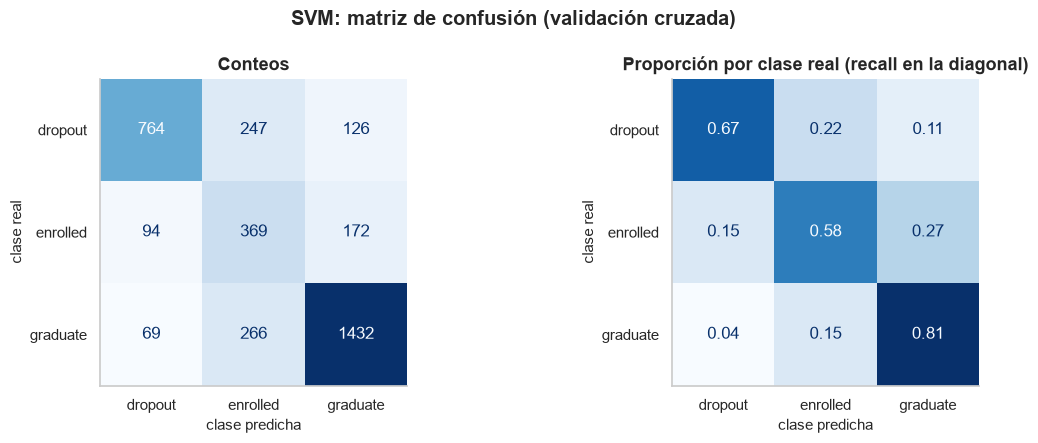

,precision,recall,f1-score,support
dropout,0.8242,0.6719,0.7403,1137.0000
enrolled,0.4184,0.5811,0.4865,635.0000
graduate,0.8277,0.8104,0.8190,1767.0000
accuracy,0.7248,0.7248,0.7248,0.7248
macro avg,0.6901,0.6878,0.6819,3539.0000
weighted avg,0.7531,0.7248,0.7340,3539.0000


In [35]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

FINAL = "SVM"
pipe_final = resultados[FINAL]["crear_pipeline"](
    optuna.trial.FixedTrial(resultados[FINAL]["study"].best_params)
)

# Predicción de cada estudiante hecha por el modelo que NO lo vio al entrenar
y_pred_cv = cross_val_predict(pipe_final, X, y, cv=PLIEGUES, n_jobs=-1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y, y_pred_cv, labels=CLASES, cmap=CMAP_CONF,
                                        ax=axes[0], colorbar=False)
axes[0].set_title("Conteos")
ConfusionMatrixDisplay.from_predictions(y, y_pred_cv, labels=CLASES, cmap=CMAP_CONF,
                                        normalize="true", values_format=".2f",
                                        ax=axes[1], colorbar=False)
axes[1].set_title("Proporción por clase real (recall en la diagonal)")
for ax in axes:
    ax.set_xlabel("clase predicha")
    ax.set_ylabel("clase real")
    ax.grid(False)
plt.suptitle(f"{FINAL}: matriz de confusión (validación cruzada)", fontweight="bold")
plt.tight_layout()
mostrar("6_2_matriz_confusion_final")

pd.DataFrame(classification_report(y, y_pred_cv, labels=CLASES, output_dict=True)).T

**Qué hace el código.**

- Reconstruye el pipeline final: el clasificador elegido en `FINAL` (el SVM) con sus mejores hiperparámetros.
- Con `cross_val_predict` obtiene, para cada estudiante, la predicción del modelo entrenado sin él (el de su pliegue de validación).
- Dibuja la matriz de confusión en conteos y normalizada por clase real, y muestra el reporte de clasificación (precisión, recall y F1 por clase).
- Guarda la figura en `Images/6_2_matriz_confusion_final.png`.

**Lectura.**

| Clase | Precisión | Recall | F1 |
|---|---|---|---|
| dropout | 0.82 | 0.67 | 0.74 |
| enrolled | 0.42 | 0.58 | 0.49 |
| graduate | 0.83 | 0.81 | 0.82 |
| **macro** | 0.69 | 0.69 | **0.682** |

- ***enrolled* es la clase difícil:** su F1 (0.49) queda muy por debajo del de las otras dos. Es el costo de `class_weight="balanced"`: el modelo predice *enrolled* 882 veces cuando en realidad hay 635 estudiantes en esa clase. Así encuentra al 58 % de ellos, pero con precisión de solo 42 %. Sin ponderar, el recall de *enrolled* sería mucho menor y el F1 macro bajaría (sección 5.2).
- **Casi todos los errores pasan por *enrolled*:** de los 974 errores, 779 (80 %) son confusiones con *enrolled*, en un sentido o en el otro. Confundir directamente un desertor con un graduado es raro: 126 desertores predichos como graduados y 69 graduados predichos como desertores (5.5 % de los estudiantes). Tiene sentido: *enrolled* queda **en medio** de las otras dos clases (ver 2.6), con algunas materias aprobadas pero no todas, y al cierre del 1er semestre muchos de estos estudiantes todavía se parecen a un desertor o a un graduado.
- **Lectura práctica para la escuela:** de los 1137 desertores, el modelo detecta como *dropout* al 67 %, y otro 22 % aparece como *enrolled*. Si la escuela contacta a todos los que **no** se predicen como *graduate*, llega al **89 % de los desertores**. Solo 126 desertores (11 %) parecen graduados al cierre del 1er semestre y pasarían sin aviso.
- El F1 macro calculado sobre todas las predicciones juntas (0.6819) coincide con el promedio de los pliegues (0.6820).

---

## 7. ¿Conviene esperar al 2º semestre?

El modelo final usa solo lo que se sabe al cierre del 1er semestre. La pregunta es cuánto mejoraría si la escuela esperara un semestre más y agregara las 6 columnas del 2º semestre (`X2`).

Para que la comparación sea justa:

- **Mismo modelo y mismos hiperparámetros:** SVM con kernel RBF y los valores de C, gamma y `class_weight` de la sección 5.2. Las 6 columnas nuevas son numéricas y se estandarizan igual que las demás. Como no se reoptimiza para `X2`, el resultado podría subestimar un poco la ganancia: con 6 columnas más, las distancias entre estudiantes crecen y el gamma óptimo podría ser algo distinto. Aun así, el SVM fue estable en la zona del óptimo (gamma entre 0.005 y 0.03, sección 5.2).
- **Mismos pliegues:** la comparación es pareada, pliegue por pliegue.

`prep_escalado` no sirve tal cual, porque su `ColumnTransformer` solo toma las columnas que se le indican y descartaría en silencio las del 2º semestre. Por eso se define un preprocesamiento que las incluye.

In [36]:
from sklearn.base import clone
from sklearn.metrics import f1_score

def prep_escalado_2do():
    """Igual que prep_escalado, pero estandariza también las 6 columnas del 2º semestre"""
    return ColumnTransformer([
        ("nominales", one_hot(), NOMINALES),
        ("continuos", StandardScaler(), CONTINUOS + cols_2do),
        ("binarios", "passthrough", BINARIOS),
    ])

pipe_2do = Pipeline([("prep", prep_escalado_2do()), ("modelo", clone(pipe_final["modelo"]))])

f1_1er = np.array(resultados[FINAL]["study"].best_trial.user_attrs["f1_pliegues"])
f1_2do = cross_val_score(pipe_2do, X2, y, cv=PLIEGUES, scoring=METRICA, n_jobs=-1)

tabla_sem = pd.DataFrame({"1er semestre": f1_1er, "1er + 2º semestre": f1_2do},
                         index=[f"pliegue {i + 1}" for i in range(len(PLIEGUES))])
tabla_sem["diferencia"] = tabla_sem["1er + 2º semestre"] - tabla_sem["1er semestre"]
tabla_sem.loc["media"] = tabla_sem.mean()
tabla_sem

,1er semestre,1er + 2º semestre,diferencia
pliegue 1,0.6701,0.6927,0.0226
pliegue 2,0.6483,0.7163,0.0679
pliegue 3,0.7113,0.7203,0.0090
pliegue 4,0.6844,0.7178,0.0334
pliegue 5,0.6958,0.7337,0.0378
media,0.6820,0.7161,0.0341


**Qué hace el código.**

- `prep_escalado_2do()` es igual a `prep_escalado()`, pero también estandariza las 6 columnas del 2º semestre.
- `pipe_2do` combina ese preprocesamiento con una copia (`clone`) del modelo final, con los mismos hiperparámetros.
- Evalúa `pipe_2do` sobre `X2` con los mismos `PLIEGUES` y lo compara pliegue por pliegue con el F1 del 1er semestre; la última fila es la media.

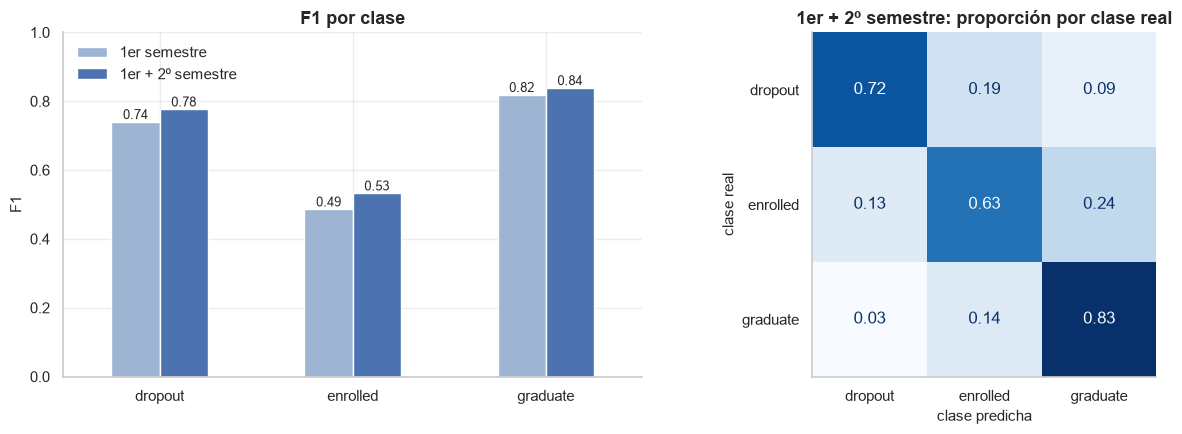

,1er semestre,1er + 2º semestre
dropout,0.7403,0.7769
enrolled,0.4865,0.5329
graduate,0.8190,0.8389


In [37]:
y_pred_2do = cross_val_predict(pipe_2do, X2, y, cv=PLIEGUES, n_jobs=-1)

f1_clase = pd.DataFrame({
    "1er semestre": f1_score(y, y_pred_cv, labels=CLASES, average=None),
    "1er + 2º semestre": f1_score(y, y_pred_2do, labels=CLASES, average=None),
}, index=CLASES)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
f1_clase.plot(kind="bar", ax=axes[0], color=["#9DB4D3", "#4C72B0"], rot=0)
for cont in axes[0].containers:
    axes[0].bar_label(cont, fmt="%.2f", fontsize=9)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("F1")
axes[0].set_title("F1 por clase")
axes[0].legend(loc="upper left")

ConfusionMatrixDisplay.from_predictions(y, y_pred_2do, labels=CLASES, cmap=CMAP_CONF,
                                        normalize="true", values_format=".2f",
                                        ax=axes[1], colorbar=False)
axes[1].set_title("1er + 2º semestre: proporción por clase real")
axes[1].set_xlabel("clase predicha")
axes[1].set_ylabel("clase real")
axes[1].grid(False)
plt.tight_layout()
mostrar("7_primer_vs_segundo_semestre")

f1_clase

**Qué hace el código.**

- Obtiene las predicciones de validación cruzada del modelo con el 2º semestre.
- Calcula el F1 de cada clase con y sin el 2º semestre y los grafica lado a lado.
- Dibuja la matriz de confusión normalizada del modelo con el 2º semestre.
- Guarda la figura en `Images/7_primer_vs_segundo_semestre.png`.

**Lectura.**

- **Esperar al 2º semestre sí mejora, pero poco:** el F1 macro pasa de 0.6820 a **0.7161 (+0.034)**. La mejora aparece en los 5 pliegues (de +0.009 a +0.068), así que es consistente y no un efecto de la partición.
- **Mejoran las tres clases en ≈ 0.02–0.05:** *dropout* de 0.74 a 0.78, *enrolled* de 0.49 a 0.53 y *graduate* de 0.82 a 0.84. *Enrolled* sigue siendo la clase difícil: con un año completo de datos, su F1 apenas pasa de 0.5 y el 38 % de esos estudiantes se sigue confundiendo con otra clase.
- **¿Por qué tan poco?** Como se vio en 2.7, las columnas del 2º semestre están muy correlacionadas con las del 1er (0.94 en materias inscritas, por ejemplo). En buena parte repiten lo que ya se sabía: quien aprobó poco en el 1er semestre suele aprobar poco en el 2º.
- **El costo de esperar:** un semestre más de espera es un semestre menos para intervenir, y parte de los desertores abandona justo durante el 2º semestre. A esa altura, la predicción llega tarde para ellos. Ganar 0.034 de F1 no compensa perder medio año de margen.

**Conclusión:** conviene predecir al cierre del 1er semestre, como hace el modelo final, y **volver a predecir** al cierre del 2º con `X2` para actualizar la lista de estudiantes en riesgo. Esperar para hacer una sola predicción no conviene.

---

## 8. Predicciones sobre el conjunto de prueba

El clasificador final (SVM con kernel RBF y los hiperparámetros de 5.2, solo con los atributos del 1er semestre) se entrena una sola vez con **los 3539 estudiantes de entrenamiento** y se usa para predecir a los 885 estudiantes de prueba. Es la primera y única vez que se toca `X_test`. Ninguna decisión de la práctica se tomó mirando el conjunto de prueba, que además no trae `Target`.

Las etiquetas se devuelven con la capitalización del archivo original (`Dropout`, `Enrolled`, `Graduate`), porque en la sección 1.4 se pasaron a minúsculas solo para trabajar.

In [38]:
modelo_final = clone(pipe_final).fit(X, y)
pred_test = modelo_final.predict(X_test)

predicciones = pd.DataFrame({"Target": pd.Series(pred_test, index=X_test.index).str.capitalize()})
predicciones.index.name = "id"

RUTA_PRED = Path("Predicciones/predicciones.csv")
RUTA_PRED.parent.mkdir(exist_ok=True)
predicciones.to_csv(RUTA_PRED)

print(f"{len(predicciones)} predicciones guardadas en {RUTA_PRED}")
comparacion = pd.DataFrame({
    "prueba (predicho)": predicciones["Target"].str.lower().value_counts(normalize=True),
    "entrenamiento (real)": y.value_counts(normalize=True),
}).loc[CLASES] * 100
comparacion.round(1)

885 predicciones guardadas en Predicciones\predicciones.csv


,prueba (predicho),entrenamiento (real)
Target,,
dropout,24.0000,32.1000
enrolled,26.0000,17.9000
graduate,50.1000,49.9000


**Qué hace el código.**

- Entrena el modelo final con los 3539 estudiantes del entrenamiento y predice a los 885 de prueba.
- Escribe las etiquetas con mayúscula inicial (`Dropout`, `Enrolled`, `Graduate`), con `id` como índice, y las guarda en `Predicciones/predicciones.csv`.
- Compara el porcentaje de cada clase predicha en prueba con el porcentaje real del entrenamiento.

**Revisión.** La distribución predicha en prueba (24.0 % *dropout*, 26.0 % *enrolled*, 50.1 % *graduate*) es parecida a la del modelo en validación cruzada (26.2 %, 24.9 % y 48.9 %; ver la matriz de confusión de 6.2). Las diferencias de 1 a 2 puntos son normales con 885 estudiantes. Como era de esperar con `class_weight="balanced"`, predice *enrolled* más que su 17.9 % real y *dropout* menos que su 32.1 %. No hay señales de un problema con los datos de prueba ni con el preprocesamiento: las categorías desconocidas de 4.4 no rompieron nada.

---

## 9. Conclusiones

1. **Clasificador final: SVM con kernel RBF** (C ≈ 1.61, gamma ≈ 0.026, `class_weight="balanced"`), con F1 macro = **0.6820 ± 0.0216** en validación cruzada estratificada de 5 pliegues, usando solo información disponible al cierre del 1er semestre.
2. **Por qué el SVM y no la regresión logística.** Los dos quedaron empatados en primer lugar, ≈ 0.04 por encima del resto:

   | | Regresión logística | SVM (RBF) |
   |---|---|---|
   | F1 macro | 0.6854 ± 0.0185 | 0.6820 ± 0.0216 |
   | Pliegues ganados | 2 de 5 | 3 de 5 |
   | F1 *dropout* / *enrolled* / *graduate* | 0.751 / 0.489 / 0.816 | 0.740 / 0.487 / 0.819 |
   | Precisión / recall de *dropout* | 0.811 / 0.699 | 0.824 / 0.672 |
   | Desertores no predichos como *graduate* | 89.8 % | 88.9 % |

   - **Es un empate:** la diferencia de F1 (0.003) es menos de un tercio de lo que varía la diferencia entre pliegues (0.011), el SVM gana en 3 de 5 pliegues, las dos desviaciones son ≈ 0.02 y los modelos predicen la misma clase en el 89 % de los estudiantes.
   - **Se desempató a favor del SVM** porque gana en más pliegues, no supone una frontera lineal (el kernel RBF capta interacciones entre atributos sin agregarlas a mano), da menos falsas alarmas de deserción (precisión de *dropout* 0.824 contra 0.811) y entrenarlo cuesta lo mismo (< 1 s).
   - **Costos aceptados:** detecta como *dropout* a unos 31 desertores menos (aunque solo 10 menos si se cuentan también los que predice como *enrolled*) y no es interpretable. Si la escuela necesitara explicar cada predicción, la logística es una alternativa equivalente.
3. **Lo que más importó no fue el modelo, sino compensar el desbalance:** `class_weight="balanced"` separó dos bandas de F1 en la logística y el SVM. Los dos modelos que no lo admiten quedaron abajo: kNN (0.573) y Naive Bayes (0.632, donde los priors uniformes no alcanzaron a compensar). En el árbol casi no influyó, porque la poda ya lo dejaba en pocas hojas.
4. **El preprocesamiento debe seguir al modelo:** kNN funcionó mucho mejor con `StandardScaler` que con `MinMaxScaler` (0.57 contra 0.52), al revés de lo que se esperaba en 4.2: lo que decide el peso de un atributo en la distancia es su varianza, no su rango (ver 2.9). El árbol no necesitó ningún preprocesamiento, y `GaussianNB` falló, como se anticipó, porque los atributos no tienen forma de campana.
5. ***Enrolled* es la clase difícil** (F1 = 0.49): queda entre desertores y graduados, y el 80 % de los errores son confusiones con ella. Desertores y graduados casi nunca se confunden entre sí (5.5 % de los estudiantes).
6. **Utilidad práctica:** si la escuela contacta a todos los estudiantes que no se predicen como *graduate*, llega al **89 % de los desertores** al cierre del 1er semestre.
7. **Esperar al 2º semestre mejora solo +0.034** en F1 macro. Conviene predecir al cierre del 1er semestre y actualizar la predicción al cierre del 2º.
8. **Señales más fuertes:** las materias aprobadas en el 1er semestre y tener la colegiatura al día. Con solo esos dos atributos y las materias inscritas, un árbol de 8 hojas llega a 0.64.

**Limitaciones:** todo el desempeño se estimó con validación cruzada, porque el conjunto de prueba no trae `Target`. El desempeño real en prueba podría ser un poco menor: el F1 reportado es el de la mejor de 60–100 configuraciones evaluadas sobre los mismos pliegues, así que tiene un ligero sesgo optimista (una validación cruzada anidada lo corregiría, a cambio de multiplicar el tiempo de cómputo). Los datos son de una sola institución en Portugal, así que los resultados pueden no aplicar en otra escuela.

---

## 10. Referencias

Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data, 7*(11), Artículo 146. https://doi.org/10.3390/data7110146

Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). *Predict students' dropout and academic success* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89


---

## 11. Declaración de uso de IA

Se utilizó **Claude Opus 5.5 (Anthropic, mediante Claude Code)** como asistente durante esta práctica.


